# LLM extraction and evaluation pipeline

**Report used:** IMF Country Report No. 24/70, *Sweden: 2024 Article IV Consultation – Press Release; and Staff Report* (March 2024).
This is the latest Article IV staff report for Sweden inside my allocated period (2023–2024).


**How to run it**
1. Use a free Gemini API key.
2. Add into Colab.

All outputs are saved to `imf_pipeline/` (in Google Drive when it is used).

## Part 0 – Setup

In [2]:
# Packages that are not pre-installed in Colab.
%pip install -q pypdf google-genai sentence-transformers faiss-cpu tiktoken

In [3]:
import os
import re
import json
import time
import random
import shutil
import hashlib
import difflib
from pathlib import Path
from typing import List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel

#related to report
COUNTRY = "Sweden"
REPORT_NAME = "IMF Country Report No. 24/70 - Sweden: 2024 Article IV Consultation"
PDF_FILENAME = "sweden_2024_article_iv.pdf"
FORECAST_YEAR = 2024
INFLATION_TARGET = 2.0

# saving files in google drive
USE_GOOGLE_DRIVE = True


def choose_base_dir():
    if USE_GOOGLE_DRIVE:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            return Path("/content/drive/MyDrive/imf_pipeline")
        except Exception as error:
            print("WARNING: Google Drive could not be connected (", error, ")")
    return Path("imf_pipeline")


BASE_DIR = choose_base_dir()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
FIG_DIR = BASE_DIR / "figures"
CACHE_DIR = BASE_DIR / "llm_cache"
for folder in [DATA_DIR, OUTPUT_DIR, FIG_DIR, CACHE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
PDF_PATH = DATA_DIR / PDF_FILENAME

# Chunking
CHUNK_TOKENS = 400
OVERLAP_TOKENS = 50

# Models
MAIN_MODEL = "gemini-3.5-flash"
JUDGE_MODEL = "gemini-3.8-flash"
BENCHMARK_MODELS = ["gemini-3.5-flash-lite", "gemini-3.5-flash", "gemini-3.8-flash"]
# Backup
BACKUP_MODELS = ["gemini-3.5-flash", "gemini-3.6-flash", "gemini-3.7-flash", "gemini-3.8-flash",
                 "gemini-3.5-flash-lite", "gemini-3.1-flash-lite"]
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

SECONDS_BETWEEN_CALLS = 4
RETRIES_PER_MODEL = 2
BENCHMARK_RETRIES = 4
BUSY_COOLDOWN_SECONDS = 900
REQUEST_TIMEOUT_SECONDS = 180
FALLBACK_VALUE = -1.0
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# One colour per series
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#7a5cc4"]

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print("Settings loaded. Outputs go to:", BASE_DIR.resolve())

Mounted at /content/drive
Settings loaded. Outputs go to: /content/drive/MyDrive/imf_pipeline


In [4]:
def clean_api_key(value):
    if value is None:
        return None
    if isinstance(value, dict):
        for name in ["GEMINI_API_KEY", "api_key"]:
            if name in value:
                return clean_api_key(value[name])
        texts = [v for v in value.values() if isinstance(v, str)]
        return clean_api_key(texts[0]) if texts else None
    text = str(value).strip().strip('"').strip("'")
    match = re.search(r"AIza[0-9A-Za-z_\-]{30,}", text)
    return match.group(0) if match else (text or None)


def get_api_key():
    key = None
    try:
        from google.colab import userdata
        key = clean_api_key(userdata.get("GEMINI_API_KEY"))
    except Exception as error:
        print("Could not read the Colab secret GEMINI_API_KEY:", type(error).__name__)
    if not key:
        key = clean_api_key(os.environ.get("GEMINI_API_KEY"))
    if not key:
        from getpass import getpass
        key = clean_api_key(getpass("Paste your Gemini API key "))
    if not key:
        print("WARNING: no Gemini API key found")
    return key


from google import genai
from google.genai import types

API_KEY = get_api_key()
try:

    client = genai.Client(api_key=API_KEY, http_options=types.HttpOptions(timeout=REQUEST_TIMEOUT_SECONDS * 1000))
except (TypeError, AttributeError):
    client = genai.Client(api_key=API_KEY)


def list_available_models():
    """Ask the API which models this key can use"""
    try:
        return {m.name.replace("models/", "") for m in client.models.list()}
    except Exception as error:
        print("Could not list models:", error)
        return set()


AVAILABLE_MODELS = list_available_models()


def resolve_model(name):
    """Return the model name """
    if not AVAILABLE_MODELS or name in AVAILABLE_MODELS:
        return name
    for backup in BACKUP_MODELS:
        if backup in AVAILABLE_MODELS:
            print(f"'{name}' is not available on this key, using '{backup}' instead")
            return backup
    return name


MAIN_MODEL = resolve_model(MAIN_MODEL)
JUDGE_MODEL = resolve_model(JUDGE_MODEL)
BENCHMARK_MODELS = list(dict.fromkeys(resolve_model(m) for m in BENCHMARK_MODELS))
if MAIN_MODEL not in BENCHMARK_MODELS:
    BENCHMARK_MODELS.append(MAIN_MODEL)
print("Main model :", MAIN_MODEL)
print("Judge model:", JUDGE_MODEL)
print("Benchmark  :", BENCHMARK_MODELS)

Main model : gemini-3.5-flash
Judge model: gemini-3.8-flash
Benchmark  : ['gemini-3.5-flash-lite', 'gemini-3.5-flash', 'gemini-3.8-flash']


### LLM helper

Every call goes through `call_llm`:


In [5]:
LLM_LOG = []
BUSY_UNTIL = {}
OUT_OF_QUOTA = set()
LAST_SUCCESS = {"writer": {}, "judge": {}}
from collections import deque
RECENT_WRITERS = deque(maxlen=6)

# words that appear in error messages
TEMPORARY_ERRORS = ["429", "500", "502", "503", "504", "UNAVAILABLE", "RESOURCE_EXHAUSTED", "overloaded",
                    "high demand", "DEADLINE_EXCEEDED", "timed out", "timeout", "disconnected", "empty response"]


def is_temporary(error):
    message = str(error).lower()
    return any(word.lower() in message for word in TEMPORARY_ERRORS)


def cache_file_for(model, prompt, system, schema_name):
    key = json.dumps({"model": model, "system": system, "prompt": prompt, "schema": schema_name}, sort_keys=True)
    return CACHE_DIR / (hashlib.sha256(key.encode("utf-8")).hexdigest()[:24] + ".json")


def models_to_try(model, allow_fallback):
    """Order in which models are tried:
    1. the requested model, unless it was overloaded in the last 15 minutes;
    2. backup models that recently answered for this role;
    3. the other backups;
    4. the recently overloaded models, as a last resort."""
    if not allow_fallback:
        return [] if model in OUT_OF_QUOTA else [model]
    role = "judge" if model == JUDGE_MODEL else "writer"
    order = [model] + [m for m in BACKUP_MODELS if m != model]
    order = [m for m in order if m not in OUT_OF_QUOTA]
    if AVAILABLE_MODELS:
        order = [m for m in order if m in AVAILABLE_MODELS or m == model]
    now = time.time()
    ready = [m for m in order if BUSY_UNTIL.get(m, 0) <= now]
    busy = [m for m in order if BUSY_UNTIL.get(m, 0) > now]
    ready.sort(key=lambda m: (m != model, -LAST_SUCCESS[role].get(m, 0)))
    busy.sort(key=lambda m: -LAST_SUCCESS[role].get(m, 0))
    if role == "writer":
        return ready + busy
    # judge: an independent model
    writers = set(RECENT_WRITERS) | {MAIN_MODEL}
    independent = [m for m in ready + busy if m not in writers]
    return independent + [m for m in ready + busy if m in writers]


def call_llm(prompt, model=None, system=None, schema=None, task="general", allow_fallback=True, retries=None):
    """Send one prompt to Gemini and return the text answer"""
    model = model or MAIN_MODEL
    schema_name = schema.__name__ if schema else None
    path = cache_file_for(model, prompt, system, schema_name)

    role = "judge" if model == JUDGE_MODEL else "writer"
    if path.exists():
        saved = json.loads(path.read_text())
        used = saved.get("model_used", model)
        # A saved answer is NOT reused when
        # (a) a benchmark call needs this exact model but a backup answered,
        # (b) the judge's saved verdict came from the same model that wrote the output (self-grading).
        wrong_model = (not allow_fallback) and used != model
        self_graded = role == "judge" and used in RECENT_WRITERS
        if not (wrong_model or self_graded):
            LLM_LOG.append({"task": task, "model": model, "model_used": used,
                            "latency_s": saved["latency_s"], "cached": True, "ok": True})
            if role == "writer":
                RECENT_WRITERS.append(used)
            return saved["text"]
        print(f"[{task}] saved answer from {used} not reused ({'different model' if wrong_model else 'self-grading'})")

    settings = {}
    if system:
        settings["system_instruction"] = system
    if schema:
        settings["response_mime_type"] = "application/json"
        settings["response_schema"] = schema
    config = types.GenerateContentConfig(**settings)

    retries = retries or RETRIES_PER_MODEL
    for candidate in models_to_try(model, allow_fallback):
        temporary = False
        for attempt in range(1, retries + 1):
            try:
                start = time.time()
                response = client.models.generate_content(model=candidate, contents=prompt, config=config)
                latency = time.time() - start
                text = response.text or ""
                if not text.strip():
                    raise ValueError("empty response")
                if candidate != model:
                    print(f"[{task}] answered by backup model {candidate} (requested {model})")
                path.write_text(json.dumps({"model": model, "model_used": candidate, "task": task,
                                            "latency_s": latency, "text": text}, indent=2))
                LLM_LOG.append({"task": task, "model": model, "model_used": candidate, "latency_s": latency,
                                "cached": False, "ok": True})
                LAST_SUCCESS[role][candidate] = time.time()
                BUSY_UNTIL.pop(candidate, None)
                if role == "writer":
                    RECENT_WRITERS.append(candidate)
                elif candidate in RECENT_WRITERS:
                    print(f"    note: judge answered with {candidate}")
                time.sleep(SECONDS_BETWEEN_CALLS)
                return text
            except Exception as error:
                message = str(error)
                temporary = is_temporary(error)
                print(f"[{task}] {candidate} attempt {attempt} failed: {message[:120]}")
                if "429" in message and "perday" in message.lower().replace(" ", ""):

                    print(f"    {candidate}: daily free quota used up")
                    OUT_OF_QUOTA.add(candidate)
                    temporary = False
                    break
                if not temporary or attempt == retries:
                    break
                wait = 10 * 2 ** (attempt - 1) + random.uniform(0, 5)
                suggested = re.search(r"retry in (\d+(?:\.\d+)?)s|retryDelay\W+(\d+)s", message)
                if suggested:
                    wait = min(60, float(suggested.group(1) or suggested.group(2)) + 1)
                print(f"    waiting {wait:.0f}s before retrying")
                time.sleep(wait)
        if temporary:
            BUSY_UNTIL[candidate] = time.time() + BUSY_COOLDOWN_SECONDS

    if model in OUT_OF_QUOTA and not allow_fallback:
        print(f"[{task}] {model} has no daily quota left '")
    print(f"[{task}] no model could answer , a fallback value will be used")
    LLM_LOG.append({"task": task, "model": model, "model_used": None, "latency_s": None, "cached": False, "ok": False})
    return ""


def parse_json(text):
    """Turn an LLM answer into a Python object."""
    if not text:
        return None
    cleaned = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.MULTILINE).strip()
    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        pass
    match = re.search(r"\{.*\}", cleaned, flags=re.DOTALL)
    if match:
        try:
            return json.loads(match.group(0))
        except json.JSONDecodeError:
            return None
    return None


def save_json(obj, filename):
    path = OUTPUT_DIR / filename
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False))
    print("saved", path)
    return path

## Part 1 – PDF Processing Pipeline & Summarisation (Task 1)

### Loading the report


In [6]:
def load_report_pdf(path):
    if path.exists() and path.read_bytes()[:4] == b"%PDF":
        print("Using saved PDF:", path)
        return path

    other_pdfs = [p for p in path.parent.glob("*.pdf") if p != path]
    if other_pdfs:
        shutil.copy(other_pdfs[0], path)
        print(f"Using {other_pdfs[0].name}, saved as {path}")
        return path

    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Please put the IMF report PDF at {path.resolve()} and run this cell again")

    print("Please upload the IMF report PDF")
    uploaded = files.upload()
    pdf_names = [name for name, content in uploaded.items() if content[:4] == b"%PDF"]
    if not pdf_names:
        raise ValueError("The uploaded file is not a PDF")
    path.write_bytes(uploaded[pdf_names[0]])
    print("Saved to", path)
    return path


def check_report(path):
    # A quick sanity check that the uploaded file is the assigned report
    from pypdf import PdfReader
    first_page = PdfReader(str(path)).pages[0].extract_text() or ""
    if COUNTRY.upper() in first_page.upper() and "ARTICLE IV" in first_page.upper():
        print("Check passed: this is an Article IV report for", COUNTRY)
    else:
        print(f"page 1 does not look like the {COUNTRY} Article IV report ")


load_report_pdf(PDF_PATH)
check_report(PDF_PATH)

Using saved PDF: /content/drive/MyDrive/imf_pipeline/data/sweden_2024_article_iv.pdf
Check passed: this is an Article IV report for Sweden


In [7]:
from pypdf import PdfReader

reader = PdfReader(str(PDF_PATH))
raw_pages = [page.extract_text() or "" for page in reader.pages]
print(f"{len(raw_pages)} pages, {sum(len(p) for p in raw_pages):,} characters of raw text")
print(raw_pages[24][:600])

56 pages, 149,935 characters of raw text
SWEDEN 
20 INTERNATIONAL MONETARY FUND 
Figure 2. Sweden: Financial Conditions 
Amid an unprecedented monetary policy tightening…  …lending rates have increased across the board… 
 
 
 
…including relative to many other advanced economies, in 
the context of short-term variable rate lending…  …while loan and bond issuances have sharply fallen… 
 
 
 
…corporate bond spreads have widened, particularly for 
HY property companies.  Bankruptcies have recently picked up. 
 
 
 
 
  
0.0
0.5
1.0
1.5
2.0
2.5
3.0
3.5
4.0
4.5
5.0
0 3 6 9 12 15 18 21 24 27 30 33
Months since the rate hiking cycle starte


### Cleaning rules

Looking at the raw text showed these problems, so each rule below targets one of them:

* **Running headers / footers**
* **Chart axis noise**
* **Contents page leaders**
* **Hard line breaks inside sentences**
* **Broken numbers in tables**
* **Words split across lines**

In [8]:
MONTHS = "Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec"
NOISE_PATTERNS = [
    rf"^{COUNTRY.upper()}$",                                    # running header
    r"^(\d+\s+)?INTERNATIONAL MONETARY FUND(\s+\d+)?$",          # running header/footer with page number
    r".*_{5,}.*",                                                # table-of-contents leaders
    r"^[-+]?\d+(\.\d+)?%?$",                                     # a lone number (axis tick / page number)
    rf"^({MONTHS})-\d{{2}}$",                                    # axis date like
    r"^(19|20)\d{2}(Q[1-4]|M\d{1,2}|H[12])?$",                   # axis year / quarter
    r"^[A-Z]{2,3}$",
    r"^[█▌\s]+$",                                                # legend symbols
]
NOISE_REGEX = [re.compile(p) for p in NOISE_PATTERNS]


def is_noise(line):
    stripped = line.strip()
    if not stripped:
        return True
    if re.fullmatch(r"[-\d.,%\s]+", stripped) and not re.fullmatch(r"((19|20)\d{2}\s*){3,}", stripped):
        return True
    return any(regex.fullmatch(stripped) for regex in NOISE_REGEX)


def is_table_row(line):
    """A table row ends with a number, has 3+ numbers, and numbers make up a big share of its words
    (so a prose sentence that happens to end with a year is not mistaken for a table row)."""
    numbers = re.findall(r"-?\d[\d,]*\.?\d*", line)
    words = line.split()
    number_like = [w for w in words if re.fullmatch(r"-?[\d,.]+|\.\.\.|…|N\.A\.|n\.a\.|-", w)]
    return (len(numbers) >= 3 and len(number_like) / max(len(words), 1) >= 0.35
            and re.search(r"(\d|\.\.\.|N\.A\.)\s*$", line) is not None)


def fix_table_numbers(line):
    line = re.sub(r"(?<![\w.])-\s+(\d)", r"-\1", line)
    line = re.sub(r"(\d)\.\s(\d)\b", r"\1.\2", line)
    line = re.sub(r"(\d),\s(\d{3})\b", r"\1,\2", line)
    return line


def is_heading(line, previous_line):
    s = line.strip()
    if re.match(r"^(Annex [IVX]+\.|Figure \d+\.|Table \d+\.|[A-D]\.\s{2,}\S)", s):
        return True
    letters = re.sub(r"[^A-Za-z]", "", s)
    if letters and s.upper() == s and len(s) < 80:         # ALL CAPS heading
        return True
    if len(s) < 45 and not re.search(r"[.,;:]$", s) and previous_line.strip().endswith(".") and s[:1].isupper():
        return True
    return False


def starts_new_block(line):
    s = line.strip()
    return bool(re.match(r"^\d{1,2}\.\s+[A-Z]", s)
                or re.match(r"^\d{1,2}\s+[A-Z]", s)
                or s.startswith("•"))


def clean_page(text):
    """Return a list of cleaned text blocks for one page."""
    lines = [l.rstrip() for l in text.replace(" ", " ").split("\n")]
    lines = [l for l in lines if not is_noise(l)]
    blocks = []
    previous = ""
    for line in lines:
        line = re.sub(r"\s{2,}", " ", line).strip()
        if is_table_row(line):
            line = fix_table_numbers(line)
        if not blocks:
            blocks.append(line)
        elif re.fullmatch(r"[A-Z]", blocks[-1]) and line[:1].islower():
            blocks[-1] += line
        elif (is_heading(line, previous) or starts_new_block(line) or is_table_row(blocks[-1])
              or is_heading(blocks[-1], "") or is_table_row(line)):
            blocks.append(line)
        elif blocks[-1].endswith("-") and line[:1].islower():
            blocks[-1] += line
        else:
            blocks[-1] += " " + line                     # same paragraph continues
        previous = line
    return [b.strip() for b in blocks if len(b.strip()) > 1]


cleaned_pages = [clean_page(t) for t in raw_pages]
raw_chars = sum(len(t) for t in raw_pages)
clean_chars = sum(len(" ".join(p)) for p in cleaned_pages)
print(f"Characters before cleaning: {raw_chars:,}  after: {clean_chars:,}  ({1 - clean_chars/raw_chars:.0%} removed)")
print("\nPDF page 30 (Table 1) after cleaning - numbers repaired:\n")
print("\n".join(cleaned_pages[29][:8]))

Characters before cleaning: 149,935  after: 135,996  (9% removed)

PDF page 30 (Table 1) after cleaning - numbers repaired:

Table 1. Sweden: Selected Economic Indicators, 2021–29
Est.
2021 2022 2023 2024 2025 2026 2027 2028 2029
Real Economy (percent change)
Real GDP 6.1 2.9 -0.3 0.2 2.3 2.2 2.2 2.1 2.1
Final domestic demand 5.7 2.4 -0.6 0.5 1.9 1.8 1.8 1.8 1.8
Private consumption 6.3 1.8 -1.7 1.1 2.2 2.3 2.2 2.2 2.2
Public consumption 3.3 -0.1 2.2 1.2 1.1 1.0 1.0 1.0 1.0


### Sections

IMF Article IV reports always have the same skeleton (press release, key issues, context,
outlook, policy discussions, staff appraisal, figures/tables, annexes). The markers below
find where each one starts.

In [9]:
# (section name, regex that matches the first block of the section)
SECTION_MARKERS = [
    ("Press Release and Executive Board Assessment", r"IMF Executive Board Concludes", True),
    ("Press Release Table", r"Table 1\. .*Selected Economic Indicators", False),
    ("Key Issues", r"KEY ISSUES$", True),
    ("Front Matter (contents, glossary)", r"Approved By", False),
    ("Context and Recent Developments", r"CONTEXT AND RECENT DEVELOPMENTS$", True),
    ("Outlook and Risks", r"OUTLOOK AND RISKS$", True),
    ("Monetary Policy", r"POLICY DISCUSSIONS$", True),
    ("Financial and Macroprudential Policies", r"B\.\s+Financial and Macroprudential", True),
    ("Fiscal Policy", r"C\.\s+Fiscal Policy", True),
    ("Macro-Structural Policies", r"D\.\s+Macro-Structural", True),
    ("Staff Appraisal", r"STAFF APPRAISAL$", True),
    ("Figures and Statistical Tables", r"Figure 1\. ", False),
    ("Annex I: Past IMF Advice", r"Annex I\. ", True),
    ("Annex II: FSAP Recommendations", r"Annex II\. ", True),
    ("Annex III: External Sector Assessment", r"Annex III\. ", True),
    ("Annex IV: Risk Assessment Matrix", r"Annex IV\. ", True),
    ("Annex V: Financial Integrity Risks", r"Annex V\. ", True),
    ("Annex VI: Debt Sustainability Analysis", r"Annex VI\. ", True),
    ("Informational Annex", r"CONSULTATION.INFORMATIONAL ANNEX|INFORMATIONAL ANNEX", True),
]


def assign_sections(pages):

    records = []
    current = "Cover"
    next_marker = 0
    for page_number, blocks in enumerate(pages, start=1):
        for block in blocks:
            for i in range(next_marker, len(SECTION_MARKERS)):
                name, pattern, _ = SECTION_MARKERS[i]
                if re.match(pattern, block):
                    current = name
                    next_marker = i + 1
                    break
            records.append({"page": page_number, "section": current, "text": block})
    return pd.DataFrame(records)


blocks_df = assign_sections(cleaned_pages)
SUMMARISE = {name: flag for name, _, flag in SECTION_MARKERS}
SUMMARISE["Cover"] = False

section_overview = (blocks_df.groupby("section", sort=False)
                    .agg(first_page=("page", "min"), last_page=("page", "max"),
                         words=("text", lambda t: sum(len(x.split()) for x in t)))
                    .reset_index())
section_overview["summarised"] = section_overview["section"].map(SUMMARISE)
missing = [name for name, _, _ in SECTION_MARKERS if name not in set(blocks_df["section"])]
print("Sections not found:", missing if missing else "none")
section_overview

Sections not found: none


,section,first_page,last_page,words,summarised
0,Cover,1,2,214,False
1,Press Release and Executive Board Assessment,2,4,1000,True
2,Press Release Table,5,6,699,False
3,Key Issues,6,6,321,True
4,"Front Matter (contents, glossary)",7,9,299,False
5,Context and Recent Developments,10,11,1036,True
6,Outlook and Risks,12,13,592,True
7,Monetary Policy,13,14,794,True
8,Financial and Macroprudential Policies,15,18,1893,True
9,Fiscal Policy,18,20,737,True


In [10]:
section_texts = {name: "\n".join(group["text"]) for name, group in blocks_df.groupby("section", sort=False)}
prose_sections = [s for s in section_texts if SUMMARISE.get(s)]

(OUTPUT_DIR / "cleaned_report.txt").write_text(
    "\n\n".join(f"### {name}\n{text}" for name, text in section_texts.items()), encoding="utf-8")
print("Prose sections that will be summarised:", len(prose_sections))

Prose sections that will be summarised: 16


### Token-aware chunking

Tokens are counted by `tiktoken`. Gemini uses its own tokenizer, so this is an approximation.

In [11]:
import tiktoken


class SimpleEncoder:
    """Backup tokenizer used only if tiktoken cannot download its vocabulary file."""
    def encode(self, text):
        return re.findall(r"\w+|[^\w\s]", text)

    def decode(self, tokens):
        return re.sub(r"\s+([^\w\s])", r"\1", " ".join(tokens))


try:
    ENCODER = tiktoken.get_encoding("cl100k_base")
except Exception as error:
    print("tiktoken vocabulary could not be downloaded, using the simple word tokenizer instead:", error)
    ENCODER = SimpleEncoder()


def count_tokens(text):
    return len(ENCODER.encode(text))


def split_long_text(text, max_tokens):

    if count_tokens(text) <= max_tokens:
        return [text]
    pieces, current = [], ""
    for sentence in re.split(r"(?<=[.!?])\s+", text):
        if count_tokens(sentence) > max_tokens:
            tokens = ENCODER.encode(sentence)
            for i in range(0, len(tokens), max_tokens):
                pieces.append(ENCODER.decode(tokens[i:i + max_tokens]))
            continue
        if count_tokens(current + " " + sentence) > max_tokens and current:
            pieces.append(current.strip())
            current = sentence
        else:
            current += " " + sentence
    if current.strip():
        pieces.append(current.strip())
    return pieces


def overlap_tail(text, n_tokens):
    """Last n tokens of a chunk"""
    tail = ENCODER.decode(ENCODER.encode(text)[-n_tokens:])
    return tail.split(" ", 1)[-1] if " " in tail else tail


def make_chunks(blocks, chunk_tokens=CHUNK_TOKENS, overlap_tokens=OVERLAP_TOKENS):
    chunks = []
    for section, group in blocks.groupby("section", sort=False):
        pieces = [(piece, row.page) for row in group.itertuples()
                  for piece in split_long_text(row.text, chunk_tokens - overlap_tokens)]
        current, pages = [], []

        def save_chunk():
            text = "\n".join(current)
            chunks.append({"chunk_id": f"C{len(chunks):03d}", "section": section,
                           "pages": f"{min(pages)}-{max(pages)}" if min(pages) != max(pages) else str(pages[0]),
                           "n_tokens": count_tokens(text), "text": text})
            return text

        for piece, page in pieces:
            if current and count_tokens("\n".join(current + [piece])) > chunk_tokens:
                previous_text = save_chunk()
                current, pages = [overlap_tail(previous_text, overlap_tokens)], [pages[-1]]
            current.append(piece)
            pages.append(page)
        if current:
            save_chunk()
    return chunks


chunks = make_chunks(blocks_df)
chunks_df = pd.DataFrame(chunks)
save_json(chunks, "chunks.json")
print(f"{len(chunks)} chunks | tokens per chunk: min {chunks_df.n_tokens.min()}, "
      f"median {chunks_df.n_tokens.median():.0f}, max {chunks_df.n_tokens.max()}")
chunks_df[["chunk_id", "section", "pages", "n_tokens"]].head(8)

saved /content/drive/MyDrive/imf_pipeline/outputs/chunks.json
120 chunks | tokens per chunk: min 96, median 358, max 400


,chunk_id,section,pages,n_tokens
0,C000,Cover,1-2,301
1,C001,Press Release and Executive Board Assessment,2,370
2,C002,Press Release and Executive Board Assessment,2,121
3,C003,Press Release and Executive Board Assessment,2-3,388
4,C004,Press Release and Executive Board Assessment,3,265
5,C005,Press Release and Executive Board Assessment,3-4,325
6,C006,Press Release Table,5,381
7,C007,Press Release Table,5,384


## Part 2 – Local vector index

Each chunk is embedded locally. Vectors are
normalised to length 1, so the L2 distance used by `faiss.IndexFlatL2` ranks chunks in exactly
the same order as cosine similarity.

In [12]:
import logging
import warnings
import faiss
from sentence_transformers import SentenceTransformer

logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*unauthenticated.*")

embedder = SentenceTransformer(EMBEDDING_MODEL)


def embed(texts):
    vectors = embedder.encode(texts, normalize_embeddings=True, show_progress_bar=False)
    return np.asarray(vectors, dtype="float32")


chunk_texts = [f"{c['section']}: {c['text']}" for c in chunks]
chunks_hash = hashlib.sha256("".join(chunk_texts).encode()).hexdigest()[:12]
embedding_file = OUTPUT_DIR / f"chunk_embeddings_{chunks_hash}.npy"

if embedding_file.exists():
    chunk_vectors = np.load(embedding_file)
    print("Loaded cached embeddings", chunk_vectors.shape)
else:
    chunk_vectors = embed(chunk_texts)
    np.save(embedding_file, chunk_vectors)
    print("Embedded chunks", chunk_vectors.shape)

index = faiss.IndexFlatL2(chunk_vectors.shape[1])
index.add(chunk_vectors)
faiss.write_index(index, str(OUTPUT_DIR / "faiss_index.bin"))


def retrieve(query, k=4):
    """Returning the k closest chunks to the query."""
    distances, ids = index.search(embed([query]), k)
    return [{**chunks[i], "distance": float(d)} for d, i in zip(distances[0], ids[0]) if i != -1]


def format_context(retrieved):
    return "\n\n".join(f"[{c['chunk_id']}] (section: {c['section']}, page {c['pages']})\n{c['text']}" for c in retrieved)


# quick check
for hit in retrieve("non-performing loans ratio", k=3):
    print(hit["chunk_id"], hit["section"], round(hit["distance"], 3), "|", hit["text"][:90].replace("\n", " "))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedded chunks (120, 384)
C074 Figures and Statistical Tables 0.911 | 7.4 7.2 Asset Quality and Exposure Non-performing loans to total gross loans 1.1 0.5 0.6 0
C065 Figures and Statistical Tables 1.023 | 6.8 6.8 Interest payments 0.2 0.5 0.7 0.7 0.6 0.6 0.5 0.5 0.5 Social benefits 15.4 15.0 14
C019 Context and Recent Developments 1.087 | lower-rated companies have largely lost access, which include some of the largest in the c


## Part 3 – Summaries and the LLM judge

### All prompts in one place

Keeping every prompt in one cell makes them easy to compare and to quote in the report.


In [13]:
SYSTEM_ANALYST = """You are a careful financial-stability analyst who works with IMF Article IV staff reports.
Rules you must always follow:
1. Use ONLY information stated in the text you are given. Never add outside knowledge, dates or numbers.
2. Copy numbers exactly as written in the source (same value, same unit, same year).
3. If something is not in the text, leave it out (or return null) rather than guessing.
4. Write in plain, neutral English."""

SYSTEM_JUDGE = """You are a strict, independent evaluator of AI-generated summaries and extractions.
You did not write the output you are checking. Judge ONLY against the SOURCE text provided,
not against your own knowledge. Be critical: give 5 only when there are no problems at all."""

PROMPTS = {
    "exec_generic": """Summarise the following IMF report.

REPORT:
{text}""",

    "exec_optimised": """Task: write an executive summary of the IMF {country} Article IV report below for a financial-stability committee.

Requirements:
- 6 to 8 bullet points, each at most 35 words.
- Focus on (a) financial-stability findings: banks, credit, real estate, household and corporate debt, and
  (b) the IMF's risk assessment: the direction of risks and the main downside and upside risks.
- Include at least 4 key numbers (for example growth, inflation, policy rate, capital ratios), copied exactly from the text.
- For every bullet, give the name of the report section it comes from.
- Do not add recommendations that the report does not make.

REPORT TEXT (sections are marked with ### headers):
{text}""",

    "section_summary": """Summarise the section "{section}" of the IMF {country} Article IV report in ONE paragraph of at most 90 words (100 is a hard limit).
- Start with the main message of the section, then the key evidence or numbers, then any policy recommendation.
- Use only facts from the section text and copy numbers exactly.
- No bullet points, no heading, and no opening such as "This section discusses".

SECTION TEXT:
{text}""",

    "shorten": """The summary below has {n_words} words but the limit is 100. Rewrite it in at most 90 words,
keeping the most important facts and numbers exactly as they are. Return only the new summary.

SUMMARY:
{summary}""",

    "judge_summary": """Evaluate the SUMMARY against the SOURCE text.

Score each criterion from 1 (very poor) to 5 (excellent):
- consistency: the summary does not contradict the source and is internally consistent.
- completeness: the most important points of the source are covered, given the length limit.
- factual_alignment: every claim and every number in the summary is supported by the source.

Also list (a) claims in the summary that are NOT supported by the source (empty list if none) and
(b) the most important points of the source that were missed. Finish with a one-sentence comment.

SOURCE:
{source}

SUMMARY:
{summary}""",
}

In [14]:

class Bullet(BaseModel):
    text: str
    source_section: str

class ExecSummary(BaseModel):
    bullets: List[Bullet]

class SummaryJudgement(BaseModel):
    consistency: int
    completeness: int
    factual_alignment: int
    unsupported_claims: List[str]
    missed_points: List[str]
    comment: str

### Checks that do not depend on an LLM

An LLM judge can be wrong or biased (for example, more lenient towards fluent text), so two simple rule-based checks run alongside it:

* **word count**
* **number support rate**

In [15]:
def word_count(text):
    return len(re.findall(r"\b\w[\w.%-]*\b", text))


def numbers_in(text):
    return re.findall(r"(?<![\w.])-?\d+(?:[.,]\d+)?", text)


def number_support_rate(summary, source):
    found = numbers_in(summary)
    if not found:
        return None
    source_numbers = set(n.replace(",", "") for n in numbers_in(source))
    supported = [n for n in found if n.replace(",", "").lstrip("-") in {s.lstrip("-") for s in source_numbers}]
    return round(len(supported) / len(found), 3)


def judge_summary(summary, source, task):
    text = call_llm(PROMPTS["judge_summary"].format(source=source, summary=summary),
                    model=JUDGE_MODEL, system=SYSTEM_JUDGE, schema=SummaryJudgement, task=task)
    result = parse_json(text)
    if not result:
        return {"consistency": None, "completeness": None, "factual_alignment": None,
                "unsupported_claims": [], "missed_points": [], "comment": "judge failed"}
    return result

### Executive summary – generic vs optimised prompt



In [16]:
report_prose = "\n\n".join(f"### {name}\n{section_texts[name]}" for name in prose_sections)
print(f"Prose given to the model: {count_tokens(report_prose):,} tokens")

exec_results = {}
for style in ["generic", "optimised"]:
    if style == "generic":
        answer = call_llm(PROMPTS["exec_generic"].format(text=report_prose), task="exec_generic")
        summary_text = answer
        bullets = [l.strip("-*• ").strip() for l in answer.split("\n") if l.strip().startswith(("-", "*", "•"))]
    else:
        answer = call_llm(PROMPTS["exec_optimised"].format(country=COUNTRY, text=report_prose),
                          system=SYSTEM_ANALYST, schema=ExecSummary, task="exec_optimised")
        parsed = parse_json(answer) or {"bullets": []}
        bullets = [f"{b['text']} ({b['source_section']})" for b in parsed["bullets"]]
        summary_text = "\n".join(f"- {b}" for b in bullets)

    judgement = judge_summary(summary_text, report_prose, task=f"judge_exec_{style}")
    exec_results[style] = {
        "summary": summary_text,
        "bullets": bullets,
        "n_bullets": len(bullets),
        "n_words": word_count(summary_text),
        "max_words_per_bullet": max([word_count(b) for b in bullets], default=0),
        "number_support_rate": number_support_rate(summary_text, report_prose),
        "judge": judgement,
    }

save_json(exec_results, "executive_summary.json")
print("\nOPTIMISED EXECUTIVE SUMMARY\n")
print(exec_results["optimised"]["summary"])

Prose given to the model: 22,294 tokens
[judge_exec_generic] gemini-3.8-flash attempt 1 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
    waiting 13s before retrying
[judge_exec_generic] gemini-3.8-flash attempt 2 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
[judge_exec_generic] answered by backup model gemini-3.6-flash (requested gemini-3.8-flash)
[judge_exec_optimised] answered by backup model gemini-3.6-flash (requested gemini-3.8-flash)
saved /content/drive/MyDrive/imf_pipeline/outputs/executive_summary.json

OPTIMISED EXECUTIVE SUMMARY

- Real GDP declined by 0.3 percent in 2023 and growth is projected to average 0.2 percent in 2024, with the balance of risks to growth tilted to the downside. (Outlook and Risks)
- Headline inflation peaked at 10.8 percent at end-2022, while the Riksbank raised its policy rate from 0 

In [17]:
exec_compare = pd.DataFrame({
    style: {"bullets": r["n_bullets"], "words": r["n_words"], "longest bullet (words)": r["max_words_per_bullet"],
            "number support rate": r["number_support_rate"],
            "judge consistency": r["judge"]["consistency"], "judge completeness": r["judge"]["completeness"],
            "judge factual alignment": r["judge"]["factual_alignment"],
            "unsupported claims flagged": len(r["judge"]["unsupported_claims"])}
    for style, r in exec_results.items()})
exec_compare

,generic,optimised
bullets,32.000,7.0
words,626.000,214.0
longest bullet (words),28.000,33.0
number support rate,0.979,1.0
judge consistency,5.000,5.0
judge completeness,5.000,4.0
judge factual alignment,5.000,5.0
unsupported claims flagged,0.000,0.0


### Section summaries with a self-correction loop

If a summary comes back over 100 words, the model is asked once more.

In [18]:
section_summaries = []
for section in prose_sections:
    source = section_texts[section]
    summary = call_llm(PROMPTS["section_summary"].format(section=section, country=COUNTRY, text=source),
                       system=SYSTEM_ANALYST, task="section_summary").strip()
    first_length = word_count(summary)
    rewritten = False
    if first_length >= 100:
        summary = call_llm(PROMPTS["shorten"].format(n_words=first_length, summary=summary),
                           system=SYSTEM_ANALYST, task="section_shorten").strip()
        rewritten = True
    if not summary:
        summary = "[summary not available - the API call failed]"

    judgement = judge_summary(summary, source, task="judge_section")
    section_summaries.append({
        "section": section,
        "source_words": word_count(source),
        "summary": summary,
        "words_first_try": first_length,
        "words_final": word_count(summary),
        "needed_rewrite": rewritten,
        "under_100_words": word_count(summary) < 100,
        "number_support_rate": number_support_rate(summary, source),
        **{k: judgement[k] for k in ["consistency", "completeness", "factual_alignment"]},
        "unsupported_claims": judgement["unsupported_claims"],
        "missed_points": judgement["missed_points"],
        "judge_comment": judgement["comment"],
    })

section_df = pd.DataFrame(section_summaries)
save_json(section_summaries, "section_summaries.json")
section_df[["section", "words_final", "needed_rewrite", "number_support_rate",
            "consistency", "completeness", "factual_alignment"]]

[judge_section] answered by backup model gemini-3.6-flash (requested gemini-3.8-flash)
saved /content/drive/MyDrive/imf_pipeline/outputs/section_summaries.json


,section,words_final,needed_rewrite,number_support_rate,consistency,completeness,factual_alignment
0,Press Release and Executive Board Assessment,95,False,1.0,5,4,5
1,Key Issues,93,False,1.0,5,5,5
2,Context and Recent Developments,92,False,1.0,5,4,5
3,Outlook and Risks,92,False,1.0,5,5,5
4,Monetary Policy,90,False,1.0,5,4,5
5,Financial and Macroprudential Policies,91,False,1.0,5,4,5
6,Fiscal Policy,90,True,1.0,5,5,5
7,Macro-Structural Policies,79,False,1.0,5,5,5
8,Staff Appraisal,87,False,1.0,5,5,5
9,Annex I: Past IMF Advice,83,False,1.0,5,5,5


In [19]:
# Print the summaries
for row in section_summaries:
    print(f"■ {row['section']}  ({row['words_final']} words, judge F/C/C = "
          f"{row['factual_alignment']}/{row['completeness']}/{row['consistency']})")
    print(row["summary"])
    if row["unsupported_claims"]:
        print("   ⚠ judge flagged:", row["unsupported_claims"])
    print()

■ Press Release and Executive Board Assessment  (95 words, judge F/C/C = 5/4/5)
Sweden’s near-term economic outlook is subdued following a 0.3 percent GDP decline in 2023, though the banking system remains resilient and inflation is receding. Growth is projected to average 0.2 percent in 2024 and 2.3 percent in 2025, while inflation is expected to average 2.6 percent in 2024 and reach target by mid-2025, down from core inflation of 5 percent y/y in December 2023. Restrictive monetary policy should remain in place during the first half of 2024, macroprudential policy settings should stay tight, and the 2024 fiscal policy stance should remain broadly neutral.

■ Key Issues  (93 words, judge F/C/C = 5/5/5)
Economic activity has weakened, leaving the near-term economic outlook subdued with downside risks. Following monetary policy tightening, GDP contracted slightly in 2023, and growth is projected to average 0.2 percent in 2024. Meanwhile, inflation has been declining after peaking at 10.

## Part 4 – Themes, insights, indicators and time series (Task 2)

### 4.1 Thematic distribution across the 7 financial-stability themes

Two measures are produced:

* **keyword density**
* **dominant theme share**

In [20]:
THEME_KEYWORDS = {
    "Inflation & Prices": ["inflation", "inflationary", "disinflation", "disinflationary", "hicp", "cpif", "cpi",
                           "consumer price", "consumer prices", "energy price", "energy prices", "price stability",
                           "deflator", "inflation expectations", "core inflation", "headline inflation"],
    "Interest Rates & Credit": ["interest rate", "interest rates", "policy rate", "monetary policy", "lending rate",
                                "lending rates", "mortgage rate", "mortgage rates", "credit", "lending", "loan", "loans",
                                "borrowing", "bond yield", "spread", "spreads", "quantitative tightening", "qt",
                                "financial conditions", "riksbank", "tightening"],
    "Housing & Real Estate": ["housing", "house price", "house prices", "real estate", "cre", "rre", "property",
                              "properties", "mortgage", "mortgages", "rent", "rents", "rent control", "rent controls",
                              "construction", "residential", "dwelling", "ltv", "loan-to-value"],
    "Banking Capital & Liquidity": ["bank", "banks", "banking", "capital", "cet1", "tier 1", "ccyb",
                                    "countercyclical buffer", "buffer", "buffers", "liquidity", "liquidity coverage",
                                    "leverage ratio", "risk weight", "risk weights", "non-performing", "npl",
                                    "provisioning", "profitability", "irb", "mrel", "deposits", "wholesale funding"],
    "Sovereign Debt": ["public debt", "government debt", "sovereign", "fiscal", "deficit", "surplus target",
                       "debt anchor", "gross financing needs", "gfn", "debt sustainability", "dsa", "budget",
                       "primary balance", "structural balance", "fiscal space", "fiscal rule"],
    "Labor Market Dynamics": ["labor market", "labour market", "unemployment", "employment", "wage", "wages",
                              "worker", "workers", "skills", "jobs", "labor force", "hours worked", "productivity",
                              "reskilling", "upskilling", "foreign-born", "employability"],
    "Systemic Financial Risk": ["systemic risk", "systemic risks", "systemic", "financial stability", "stress test",
                                "stress tests", "contagion", "vulnerability", "vulnerabilities", "macroprudential",
                                "fsap", "spillover", "spillovers", "crisis", "resolution", "nbfi", "nbfis", "cyber",
                                "interconnectedness", "money laundering", "aml/cft"],
}
THEMES = list(THEME_KEYWORDS)


def theme_regex(words):
    words = sorted(words, key=len, reverse=True)
    return re.compile(r"(?<![\w-])(" + "|".join(re.escape(w) for w in words) + r")(?![\w-])", re.IGNORECASE)


THEME_REGEX = {theme: theme_regex(words) for theme, words in THEME_KEYWORDS.items()}


def count_themes(text):
    return {theme: len(regex.findall(text)) for theme, regex in THEME_REGEX.items()}


# counts per chunk
theme_rows = []
for c in chunks:
    counts = count_themes(c["text"])
    top = max(counts, key=counts.get) if max(counts.values()) > 0 else "None"
    theme_rows.append({"chunk_id": c["chunk_id"], "section": c["section"], "words": word_count(c["text"]),
                       **counts, "dominant_theme": top})
theme_chunk_df = pd.DataFrame(theme_rows)

# for overlap and de-duplication
total_counts = count_themes("\n".join(section_texts.values()))
total_words = word_count("\n".join(section_texts.values()))
theme_summary = pd.DataFrame({
    "theme": THEMES,
    "keyword_matches": [total_counts[t] for t in THEMES],
    "density_per_1000_words": [round(total_counts[t] / total_words * 1000, 2) for t in THEMES],
    "dominant_in_share_of_chunks": [round((theme_chunk_df["dominant_theme"] == t).mean(), 3) for t in THEMES],
})
theme_summary["share_of_matches_pct"] = (theme_summary["keyword_matches"] / theme_summary["keyword_matches"].sum() * 100).round(1)


theme_by_section = pd.DataFrame(
    {name: count_themes(text) for name, text in section_texts.items()}).T
theme_by_section.index.name = "section"

save_json({"total_words": total_words,
           "themes": theme_summary.to_dict(orient="records"),
           "by_section": theme_by_section.reset_index().to_dict(orient="records"),
           "keywords": THEME_KEYWORDS}, "thematic_distribution.json")
theme_summary.sort_values("density_per_1000_words", ascending=False)

saved /content/drive/MyDrive/imf_pipeline/outputs/thematic_distribution.json


,theme,keyword_matches,density_per_1000_words,dominant_in_share_of_chunks,share_of_matches_pct
3,Banking Capital & Liquidity,286,13.71,0.275,23.5
1,Interest Rates & Credit,211,10.12,0.150,17.3
2,Housing & Real Estate,188,9.01,0.117,15.4
6,Systemic Financial Risk,157,7.53,0.042,12.9
0,Inflation & Prices,145,6.95,0.158,11.9
4,Sovereign Debt,143,6.86,0.142,11.7
5,Labor Market Dynamics,88,4.22,0.042,7.2


### 4.2 Qualitative insights: strengths and vulnerabilities



In [21]:
PROMPTS["insights"] = """From the IMF {country} report text below, extract:
1. growth_drivers_strengths: 5 to 7 national macroeconomic strengths or growth drivers
   (for example strong bank capital buffers, fiscal space).
2. vulnerabilities_challenges: 5 to 7 systemic vulnerabilities or challenges
   (for example commercial real estate debt, geopolitical supply shocks).

For each item give:
- title: a short label (max 8 words)
- explanation: one sentence in your own words (max 30 words)
- evidence_quote: a SHORT exact quote (max 25 words) copied word-for-word from the text
- section: the section the quote comes from

Do not list the same idea twice. Use the narrative text, not the tables.

REPORT TEXT:
{text}"""


class Insight(BaseModel):
    title: str
    explanation: str
    evidence_quote: str
    section: str

class InsightList(BaseModel):
    growth_drivers_strengths: List[Insight]
    vulnerabilities_challenges: List[Insight]


def normalise(text):
    text = text.lower().replace("’", "'").replace("–", "-").replace("—", "-")
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9%.,' -]", " ", text)).strip()


NORMALISED_REPORT = normalise("\n".join(section_texts.values()))
REPORT_WORDS = NORMALISED_REPORT.split()


def verify_quote(quote, threshold=0.85):
    q = normalise(quote)
    if not q:
        return False, 0.0
    if q in NORMALISED_REPORT:
        return True, 1.0
    q_words = q.split()
    anchors = set(q_words[:3])
    best = 0.0
    for i, word in enumerate(REPORT_WORDS):
        if word in anchors:
            window = " ".join(REPORT_WORDS[i:i + len(q_words)])
            best = max(best, difflib.SequenceMatcher(None, q, window).ratio())
    return best >= threshold, round(best, 3)


answer = call_llm(PROMPTS["insights"].format(country=COUNTRY, text=report_prose),
                  system=SYSTEM_ANALYST, schema=InsightList, task="insights")
insights = parse_json(answer) or {"growth_drivers_strengths": [], "vulnerabilities_challenges": []}

insight_rows = []
for kind in ["growth_drivers_strengths", "vulnerabilities_challenges"]:
    insights[kind] = insights[kind][:7]
    for item in insights[kind]:
        ok, similarity = verify_quote(item["evidence_quote"])
        item["quote_verified"] = ok
        item["quote_similarity"] = similarity
        insight_rows.append({"type": "strength" if kind.startswith("growth") else "vulnerability", **item})

insights_df = pd.DataFrame(insight_rows)
save_json(insights, "qualitative_insights.json")
print(f"Quotes verified in the source: {insights_df['quote_verified'].mean():.0%}" if len(insights_df) else "no insights")
insights_df[["type", "title", "section", "quote_verified", "quote_similarity"]]

saved /content/drive/MyDrive/imf_pipeline/outputs/qualitative_insights.json
Quotes verified in the source: 100%


,type,title,section,quote_verified,quote_similarity
0,strength,Strong Banking System Capital and Liquidity Bu...,Press Release and Executive Board Assessment,True,1.0
1,strength,Substantial Fiscal Space,Key Issues,True,1.0
2,strength,Strong External Current Account Position,Press Release and Executive Board Assessment,True,1.0
3,strength,Competitive Manufacturing Sector and Skilled L...,Context and Recent Developments,True,1.0
4,strength,Relatively High Household Wealth,Financial and Macroprudential Policies,True,1.0
5,strength,Adequate Foreign Currency Reserves,Context and Recent Developments,True,1.0
6,vulnerability,Severely Strained Commercial Real Estate Sector,Press Release and Executive Board Assessment,True,1.0
7,vulnerability,High Household Debt and Mortgage Vulnerabilities,Press Release and Executive Board Assessment,True,1.0
8,vulnerability,Sharp Increase in Corporate Bankruptcies,Context and Recent Developments,True,1.0
9,vulnerability,Labor Market Mismatches and Structural Unemplo...,Macro-Structural,True,1.0


### 4.3 Core indicators as strict JSON (with RAG context, a model benchmark and fallbacks)



In [22]:
INDICATOR_FIELDS = ["gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct",
                    "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio"]

INDICATOR_QUERIES = {
    "gdp_growth_forecast_pct": f"real GDP growth projected for {FORECAST_YEAR} and the following year",
    "headline_inflation_rate_pct": "headline HICP inflation average annual rate",
    "central_bank_policy_rate_pct": "Riksbank policy rate raised to percent",
    "non_performing_loan_ratio": "non-performing loans share of total gross loans",
    "unemployment_rate_pct": "unemployment rate percent labor market",
    "tier_1_capital_ratio": "regulatory tier 1 capital to risk-weighted assets capital adequacy",
}

PROMPTS["indicators_generic"] = """Extract these indicators for {country} as JSON: country_name, gdp_growth_forecast_pct,
headline_inflation_rate_pct, central_bank_policy_rate_pct, non_performing_loan_ratio, unemployment_rate_pct, tier_1_capital_ratio.

CONTEXT:
{context}"""

PROMPTS["indicators_optimised"] = """Extract core economic indicators for {country} from the CONTEXT passages of an IMF Article IV report.

Use these exact definitions:
- gdp_growth_forecast_pct: IMF staff projection of real GDP growth for {year} (percent).
- headline_inflation_rate_pct: headline inflation (HICP or CPI), ANNUAL AVERAGE for the most recent full year of
  actual data. Not core inflation, not a monthly year-on-year figure, not a projection.
- central_bank_policy_rate_pct: the current central bank policy rate (percent).
- non_performing_loan_ratio: non-performing loans as a percent of total gross loans, latest value.
- unemployment_rate_pct: unemployment rate, ANNUAL AVERAGE for the most recent full year of actual data.
- tier_1_capital_ratio: regulatory Tier 1 capital to risk-weighted assets, latest value. Not CET1, not total capital.

Rules:
- Only use numbers that appear in the CONTEXT. If a value is not there, set value to null and say why in note.
- For each value give the period it refers to and the exact table row or sentence it comes from as evidence.
- Write percentages as printed (4.0, not 0.04).

CONTEXT:
{context}"""

PROMPTS["judge_indicators"] = """Audit the EXTRACTED indicators against the SOURCE passages.
The intended definitions are:
{definitions}

For every field decide:
- "correct": the value matches the source under the definition,
- "incorrect": the source supports a different value (give that value in correct_value),
- "not_in_source": the source does not contain this value.
Then give an overall score from 1 (unreliable) to 5 (fully correct).

SOURCE:
{context}

EXTRACTED:
{extracted}"""


class IndicatorValue(BaseModel):
    value: Optional[float]
    period: Optional[str]
    evidence: Optional[str]
    note: Optional[str]

class IndicatorExtraction(BaseModel):
    country_name: str
    gdp_growth_forecast_pct: IndicatorValue
    headline_inflation_rate_pct: IndicatorValue
    central_bank_policy_rate_pct: IndicatorValue
    non_performing_loan_ratio: IndicatorValue
    unemployment_rate_pct: IndicatorValue
    tier_1_capital_ratio: IndicatorValue

class FieldVerdict(BaseModel):
    field: str
    verdict: str
    correct_value: Optional[float]
    comment: str

class IndicatorAudit(BaseModel):
    verdicts: List[FieldVerdict]
    overall_score: int


# Building shared context with RAG
indicator_chunks = {}
for field, query in INDICATOR_QUERIES.items():
    for hit in retrieve(query, k=4):
        indicator_chunks.setdefault(hit["chunk_id"], hit)
indicator_context = format_context(list(indicator_chunks.values()))
DEFINITIONS_TEXT = PROMPTS["indicators_optimised"].split("Use these exact definitions:")[1].split("Rules:")[0].format(year=FORECAST_YEAR)
print(f"Indicator context: {len(indicator_chunks)} chunks, {count_tokens(indicator_context):,} tokens")

Indicator context: 23 chunks, 8,270 tokens


In [23]:
MANUAL_GROUND_TRUTH = {
    "country_name": COUNTRY,
    "gdp_growth_forecast_pct": 0.2,
    "headline_inflation_rate_pct": 5.9,
    "central_bank_policy_rate_pct": 4.0,
    "non_performing_loan_ratio": 0.3,
    "unemployment_rate_pct": 7.7,
    "tier_1_capital_ratio": 20.8,
}
TOLERANCE = 0.05


def check_value(value):
    if value is None:
        return FALLBACK_VALUE, "missing (null) in model output"
    try:
        number = float(str(value).replace("%", "").strip())
    except ValueError:
        return FALLBACK_VALUE, f"not a number: {value!r}"
    if number < -20 or number > 100:
        return FALLBACK_VALUE, f"out of plausible range: {number}"
    if 0 < abs(number) < 0.1 and number != 0:
        return FALLBACK_VALUE, f"looks like a fraction instead of a percent: {number}"
    return number, None


def flatten_extraction(parsed):
    """Turn either output style into the flat target schema"""
    flat = {"country_name": COUNTRY}
    details, fallbacks = {}, {}
    if not isinstance(parsed, dict):
        for field in INDICATOR_FIELDS:
            flat[field] = FALLBACK_VALUE
            fallbacks[field] = "model output was not valid JSON"
        return flat, details, fallbacks
    flat["country_name"] = str(parsed.get("country_name") or COUNTRY)
    for field in INDICATOR_FIELDS:
        entry = parsed.get(field)
        raw = entry.get("value") if isinstance(entry, dict) else entry
        number, problem = check_value(raw)
        flat[field] = number
        details[field] = entry if isinstance(entry, dict) else {"value": entry}
        if problem:
            note = entry.get("note") if isinstance(entry, dict) else None
            fallbacks[field] = problem + (f" | model note: {note}" if note else "")
    return flat, details, fallbacks


def schema_compliance(parsed):
    if not isinstance(parsed, dict):
        return 0.0
    ok = isinstance(parsed.get("country_name"), str)
    for field in INDICATOR_FIELDS:
        entry = parsed.get(field)
        raw = entry.get("value") if isinstance(entry, dict) else entry
        ok_field = isinstance(raw, (int, float)) and not isinstance(raw, bool)
        ok += ok_field
    return round(ok / 7, 3)

In [24]:
benchmark_rows, extraction_runs = [], {}

for model in BENCHMARK_MODELS:
    for style in ["generic", "optimised"]:
        run_name = f"{model} | {style}"
        if style == "generic":
            text = call_llm(PROMPTS["indicators_generic"].format(country=COUNTRY, context=indicator_context),
                            model=model, task="indicators_generic", allow_fallback=False, retries=BENCHMARK_RETRIES)
        else:
            text = call_llm(PROMPTS["indicators_optimised"].format(country=COUNTRY, year=FORECAST_YEAR,
                                                                    context=indicator_context),
                            model=model, system=SYSTEM_ANALYST, schema=IndicatorExtraction, task="indicators_optimised",
                            allow_fallback=False, retries=BENCHMARK_RETRIES)
        latency = LLM_LOG[-1]["latency_s"]
        parsed = parse_json(text)
        flat, details, fallbacks = flatten_extraction(parsed)

        status = "ok" if text else "no response (model unavailable)"

        # second LLM audits the extraction
        if text:
            audit_text = call_llm(PROMPTS["judge_indicators"].format(definitions=DEFINITIONS_TEXT, context=indicator_context,
                                                                     extracted=json.dumps(flat, indent=2)),
                                  model=JUDGE_MODEL, system=SYSTEM_JUDGE, schema=IndicatorAudit, task="judge_indicators")
            audit = parse_json(audit_text) or {"verdicts": [], "overall_score": None}
        else:
            audit = {"verdicts": [], "overall_score": None}
        verdict_by_field = {v["field"]: v["verdict"] for v in audit["verdicts"]}

        extraction_runs[run_name] = {"model": model, "prompt_style": style, "indicators": flat,
                                     "details": details, "fallbacks": fallbacks, "judge_audit": audit,
                                     "status": status, "raw_output": text}
        benchmark_rows.append({"run": run_name, "model": model, "prompt_style": style, "status": status,
                               "schema_compliance": schema_compliance(parsed),
                               "latency_s": round(latency, 2) if latency else None,
                               "n_fallbacks": len(fallbacks),
                               "judge_overall": audit["overall_score"],
                               "judge_share_correct": round(np.mean([verdict_by_field.get(f) == "correct"
                                                                     for f in INDICATOR_FIELDS]), 3),
                               **{f: flat[f] for f in INDICATOR_FIELDS}})

benchmark_wide = pd.DataFrame(benchmark_rows)
benchmark_wide[["run", "status", "schema_compliance", "latency_s", "n_fallbacks", "judge_overall"] + INDICATOR_FIELDS]

,run,status,schema_compliance,latency_s,n_fallbacks,judge_overall,gdp_growth_forecast_pct,headline_inflation_rate_pct,central_bank_policy_rate_pct,non_performing_loan_ratio,unemployment_rate_pct,tier_1_capital_ratio
0,gemini-3.5-flash-lite | generic,ok,1.0,1.64,0,3,0.2,2.6,4.0,0.3,8.4,20.8
1,gemini-3.5-flash-lite | optimised,ok,1.0,2.76,0,5,0.2,5.9,4.0,0.3,7.7,20.8
2,gemini-3.5-flash | generic,ok,1.0,9.35,0,3,0.2,2.6,4.0,0.3,8.4,20.8
3,gemini-3.5-flash | optimised,ok,1.0,13.09,0,5,0.2,5.9,4.0,0.3,7.7,20.8
4,gemini-3.8-flash | generic,ok,1.0,36.90,0,5,0.2,5.9,4.0,0.3,7.7,20.8
5,gemini-3.8-flash | optimised,ok,1.0,101.28,0,5,0.2,5.9,4.0,0.3,7.7,20.8


**Tidy (long) format**

In [25]:
indicator_long = benchmark_wide.melt(id_vars=["run", "model", "prompt_style"], value_vars=INDICATOR_FIELDS,
                                     var_name="indicator", value_name="extracted_value")
indicator_long["true_value"] = indicator_long["indicator"].map(MANUAL_GROUND_TRUTH)
indicator_long["is_fallback"] = indicator_long["extracted_value"] == FALLBACK_VALUE
indicator_long["correct"] = (indicator_long["extracted_value"] - indicator_long["true_value"]).abs() <= TOLERANCE

# what the judge say about each field?
indicator_long["judge_verdict"] = [
    {v["field"]: v["verdict"] for v in extraction_runs[r]["judge_audit"]["verdicts"]}.get(f, "missing")
    for r, f in zip(indicator_long["run"], indicator_long["indicator"])]
indicator_long["judge_says_correct"] = indicator_long["judge_verdict"] == "correct"
indicator_long["status"] = indicator_long["run"].map(dict(zip(benchmark_wide["run"], benchmark_wide["status"])))

failed = indicator_long["status"] != "ok"
indicator_long["judge_says_correct"] = indicator_long["judge_says_correct"].astype(float).where(~failed)
indicator_long["correct"] = indicator_long["correct"].astype(float).where(~failed)
indicator_long["judge_agrees_with_me"] = (indicator_long["judge_says_correct"] == indicator_long["correct"]).astype(float).where(~failed)

accuracy_table = (indicator_long.groupby(["run", "model", "prompt_style"], sort=False)
                  .agg(accuracy=("correct", "mean"), judge_estimated_accuracy=("judge_says_correct", "mean"),
                       judge_agreement=("judge_agrees_with_me", "mean"), fallbacks=("is_fallback", "sum"))
                  .reset_index())
accuracy_table = accuracy_table.merge(benchmark_wide[["run", "status", "schema_compliance", "latency_s"]], on="run")
indicator_long.to_csv(OUTPUT_DIR / "indicator_benchmark_long.csv", index=False)
accuracy_table.round(3)

,run,model,prompt_style,accuracy,judge_estimated_accuracy,judge_agreement,fallbacks,status,schema_compliance,latency_s
0,gemini-3.5-flash-lite | generic,gemini-3.5-flash-lite,generic,0.667,0.667,1.0,0,ok,1.0,1.64
1,gemini-3.5-flash-lite | optimised,gemini-3.5-flash-lite,optimised,1.000,1.000,1.0,0,ok,1.0,2.76
2,gemini-3.5-flash | generic,gemini-3.5-flash,generic,0.667,0.667,1.0,0,ok,1.0,9.35
3,gemini-3.5-flash | optimised,gemini-3.5-flash,optimised,1.000,1.000,1.0,0,ok,1.0,13.09
4,gemini-3.8-flash | generic,gemini-3.8-flash,generic,1.000,1.000,1.0,0,ok,1.0,36.90
5,gemini-3.8-flash | optimised,gemini-3.8-flash,optimised,1.000,1.000,1.0,0,ok,1.0,101.28


In [26]:
# Which fields were wrong, and what did the judge think?
errors = indicator_long[(indicator_long["correct"] == 0) & (indicator_long["status"] == "ok")][
    ["run", "indicator", "extracted_value", "true_value", "judge_verdict"]]
print("Disagreements between the extraction and my manual check:")
errors if len(errors) else print("none")

Disagreements between the extraction and my manual check:


,run,indicator,extracted_value,true_value,judge_verdict
6,gemini-3.5-flash-lite | generic,headline_inflation_rate_pct,2.6,5.9,incorrect
8,gemini-3.5-flash | generic,headline_inflation_rate_pct,2.6,5.9,incorrect
24,gemini-3.5-flash-lite | generic,unemployment_rate_pct,8.4,7.7,incorrect
26,gemini-3.5-flash | generic,unemployment_rate_pct,8.4,7.7,incorrect


In [27]:

main_run = extraction_runs[f"{MAIN_MODEL} | optimised"]
main_run["model_used"] = MAIN_MODEL

if len(main_run["fallbacks"]) == len(INDICATOR_FIELDS) and not main_run["raw_output"]:
    print("Main model gave no answer in the benchmark - extracting again with backup models allowed")
    text = call_llm(PROMPTS["indicators_optimised"].format(country=COUNTRY, year=FORECAST_YEAR, context=indicator_context),
                    system=SYSTEM_ANALYST, schema=IndicatorExtraction, task="indicators_final_retry")
    flat, details, fallbacks = flatten_extraction(parse_json(text))
    audit = parse_json(call_llm(PROMPTS["judge_indicators"].format(definitions=DEFINITIONS_TEXT, context=indicator_context,
                                                                    extracted=json.dumps(flat, indent=2)),
                                model=JUDGE_MODEL, system=SYSTEM_JUDGE, schema=IndicatorAudit,
                                task="judge_indicators_final")) or {"verdicts": [], "overall_score": None}
    main_run = {**main_run, "indicators": flat, "details": details, "fallbacks": fallbacks,
                "judge_audit": audit, "model_used": LLM_LOG[-2]["model_used"]}

final_indicators = main_run["indicators"]
save_json(final_indicators, "core_indicators.json")
save_json({"indicators": final_indicators,
           "evidence": main_run["details"],
           "fallbacks": main_run["fallbacks"],
           "fallback_value": FALLBACK_VALUE,
           "model_used": main_run["model_used"],
           "judge_audit": main_run["judge_audit"],
           "manual_ground_truth": MANUAL_GROUND_TRUTH}, "core_indicators_audited.json")
save_json({run: {k: v for k, v in r.items() if k != "raw_output"} for run, r in extraction_runs.items()},
          "indicator_benchmark_runs.json")
print(json.dumps(final_indicators, indent=2))
print("Fallbacks used:", main_run["fallbacks"] or "none")

saved /content/drive/MyDrive/imf_pipeline/outputs/core_indicators.json
saved /content/drive/MyDrive/imf_pipeline/outputs/core_indicators_audited.json
saved /content/drive/MyDrive/imf_pipeline/outputs/indicator_benchmark_runs.json
{
  "country_name": "Sweden",
  "gdp_growth_forecast_pct": 0.2,
  "headline_inflation_rate_pct": 5.9,
  "central_bank_policy_rate_pct": 4.0,
  "non_performing_loan_ratio": 0.3,
  "unemployment_rate_pct": 7.7,
  "tier_1_capital_ratio": 20.8
}
Fallbacks used: none


### 4.4 Time series for longitudinal plots



In [28]:
def find_table_text(title_pattern):
    matches = [i for i, blocks in enumerate(cleaned_pages) if any(re.match(title_pattern, b) for b in blocks)]
    if not matches:
        print("table not found:", title_pattern)
        return ""
    return "\n".join(cleaned_pages[matches[-1]])


TABLE_TITLES = {
    "Table 1 (Selected Economic Indicators)": r"Table 1\. .*Selected Economic Indicators",
    "Table 4 (Depository Corporations Survey)": r"Table 4\. .*Depository Corporations",
    "Table 5 (Financial Soundness Indicators)": r"Table 5\. .*Financial Soundness",
}
tables_text = "\n\n".join(f"===== {name} =====\n{find_table_text(p)}" for name, p in TABLE_TITLES.items())

TREND_SERIES = {
    "real_gdp_growth": "Table 1: Real GDP (percent change)",
    "hicp_inflation_avg": "Table 1: HICP inflation (average)",
    "core_inflation_avg": "Table 1: HICP core inflation (average)",
    "unemployment_rate": "Table 1: Unemployment rate (percent)",
    "policy_rate": "Table 1: Policy rate (percent, end of period)",
    "ten_year_bond_yield": "Table 1: Ten-year government bond yield",
    "mortgage_lending_rate": "Table 1: Mortgage lending rate",
    "gov_gross_debt_pct_gdp": "Table 1: General government gross debt",
    "bank_lending_households_growth": "Table 1: Bank lending to households (y/y percent change)",
    "private_credit_growth": "Table 4: Claims on private sector, ANNUAL PERCENTAGE CHANGE block (not billions of SEK or USD)",
    "npl_ratio": "Table 5: Non-performing loans to total gross loans",
    "tier1_capital_ratio": "Table 5: Regulatory tier 1 capital to risk-weighted assets",
    "household_debt_pct_disposable_income": "Table 5: Total household debt (in percent of disposable income)",
    "house_price_change": "Table 5: Change in housing price index",
}

PROMPTS["trends"] = """Below are statistical tables from an IMF report. Extract the time series listed, exactly as printed.

Series to extract (series_key: where to find it):
{series_list}

Rules:
- Return every year column shown for that row, in order, as 4-digit strings.
- Use null for "...", "N.A." or empty cells. Copy numbers exactly, keep minus signs, never compute or interpolate.
- first_projection_year: the first year that is a projection (Table 1 has projections), otherwise null.

TABLES:
{tables}"""


class TimeSeries(BaseModel):
    series_key: str
    source_table: str
    years: List[str]
    values: List[Optional[float]]
    first_projection_year: Optional[str]

class TrendExtraction(BaseModel):
    series: List[TimeSeries]


series_list = "\n".join(f"- {k}: {v}" for k, v in TREND_SERIES.items())
text = call_llm(PROMPTS["trends"].format(series_list=series_list, tables=tables_text),
                system=SYSTEM_ANALYST, schema=TrendExtraction, task="trends")
trend_output = parse_json(text) or {"series": []}

table_numbers = set(n.replace(",", "") for n in numbers_in(tables_text))
trend_rows, trend_checks = [], []
for s in trend_output["series"]:
    if s["series_key"] not in TREND_SERIES or len(s["years"]) != len(s["values"]):
        trend_checks.append({"series_key": s["series_key"], "status": "dropped (unknown key or length mismatch)"})
        continue
    traced = [v is None or f"{v:.1f}" in table_numbers or str(v) in table_numbers for v in s["values"]]
    trend_checks.append({"series_key": s["series_key"], "status": "kept", "n_points": len(s["years"]),
                         "traceable_share": round(np.mean(traced), 3)})
    row = {"series_key": s["series_key"], "source_table": s["source_table"],
           "first_projection_year": s["first_projection_year"]}
    row.update({year: value for year, value in zip(s["years"], s["values"])})
    trend_rows.append(row)

trends_wide = pd.DataFrame(trend_rows, columns=["series_key", "source_table", "first_projection_year"] +
                           sorted({k for r in trend_rows for k in r} - {"series_key", "source_table", "first_projection_year"}))
missing_series = sorted(set(TREND_SERIES) - set(trends_wide.get("series_key", [])))
print("Series not extracted:", missing_series or "none")
pd.DataFrame(trend_checks)

Series not extracted: none


,series_key,status,n_points,traceable_share
0,real_gdp_growth,kept,9,1.0
1,hicp_inflation_avg,kept,9,1.0
2,core_inflation_avg,kept,9,1.0
3,unemployment_rate,kept,9,1.0
4,policy_rate,kept,9,1.0
5,ten_year_bond_yield,kept,9,1.0
6,mortgage_lending_rate,kept,9,1.0
7,gov_gross_debt_pct_gdp,kept,9,1.0
8,bank_lending_households_growth,kept,9,1.0
9,private_credit_growth,kept,5,1.0


In [29]:

year_columns = sorted([c for c in trends_wide.columns if re.fullmatch(r"(19|20)\d{2}", str(c))])
trends_long = trends_wide.melt(id_vars=["series_key", "source_table", "first_projection_year"],
                               value_vars=year_columns, var_name="year", value_name="value")
trends_long = trends_long.dropna(subset=["value"])
trends_long["year"] = trends_long["year"].astype(int)
trends_long["is_projection"] = [bool(p) and y >= int(p) for p, y in
                                zip(trends_long["first_projection_year"].fillna(""), trends_long["year"])]
trends_long = trends_long.sort_values(["series_key", "year"]).reset_index(drop=True)

trends_long.to_csv(OUTPUT_DIR / "trends_long.csv", index=False)
save_json({"series": trend_output["series"], "checks": trend_checks}, "temporal_trends.json")
trends_long.pivot(index="series_key", columns="year", values="value")

saved /content/drive/MyDrive/imf_pipeline/outputs/temporal_trends.json


year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029
series_key,,,,,,,,,,,,,
bank_lending_households_growth,NaN,NaN,NaN,NaN,6.7,3.5,0.3,NaN,NaN,NaN,NaN,NaN,NaN
core_inflation_avg,NaN,NaN,NaN,NaN,1.6,5.5,7.4,3.5,2.2,2.0,2.0,2.0,2.0
gov_gross_debt_pct_gdp,NaN,NaN,NaN,NaN,36.5,32.9,34.0,34.5,33.5,32.4,31.3,30.3,29.4
hicp_inflation_avg,NaN,NaN,NaN,NaN,2.7,8.1,5.9,2.6,2.0,2.0,2.0,2.0,2.0
house_price_change,6.6,-0.9,2.5,4.2,10.1,3.6,-5.0,NaN,NaN,NaN,NaN,NaN,NaN
household_debt_pct_disposable_income,187.3,188.8,189.8,200.1,201.8,196.0,189.0,NaN,NaN,NaN,NaN,NaN,NaN
mortgage_lending_rate,NaN,NaN,NaN,NaN,1.4,3.4,4.7,NaN,NaN,NaN,NaN,NaN,NaN
npl_ratio,1.1,0.5,0.6,0.5,0.4,0.3,0.3,NaN,NaN,NaN,NaN,NaN,NaN
policy_rate,NaN,NaN,NaN,NaN,0.0,2.5,4.0,NaN,NaN,NaN,NaN,NaN,NaN


## Part 5 – Grounded question answering with RAG (Task 3) and Multi-Query RAG (extension)

In [30]:
RAG_QUESTIONS = [
    {"id": "Q1", "question": "What has happened to the countercyclical capital buffer and the risk weight floors, and what further capital measures does the IMF recommend for banks' commercial real estate exposures?",
     "key_facts": ["2 percent", "risk weight floor", "25 percent", "35 percent", "systemic risk buffer"]},
    {"id": "Q2", "question": "What assumptions does the FSAP adverse stress test scenario make, and how much could the banks' CET1 ratio fall?",
     "key_facts": ["400 bp", "38 percent", "three standard deviation", "620", "800"]},
    {"id": "Q3", "question": "When is inflation expected to return to the 2 percent target, and what does this mean for monetary policy?",
     "key_facts": ["mid-2025", "first half of 2024", "2.6 percent", "data dependent"]},
    {"id": "Q4", "question": "Why is the commercial real estate sector under pressure and how are banks exposed to it?",
     "key_facts": ["lower-rated", "200 bps", "vacancies", "47 percent", "bond"]},
    {"id": "Q5", "question": "What is the IMF's view on Sweden's fiscal stance in 2024 and its fiscal space?",
     "key_facts": ["neutral", "0.7 percent", "fiscal space", "surplus target"]},
    {"id": "Q6", "question": "How indebted are Swedish households and how sensitive are they to higher interest rates?",
     "key_facts": ["187 percent", "75 percent", "90 percent", "two years or less", "8 percent"]},
]

PROMPTS["rag_answer"] = """Answer the QUESTION using only the CONTEXT passages from the IMF {country} Article IV report.
- Cite the chunk ids you used in square brackets, e.g. [C012].
- If the context does not contain the answer, say "The provided excerpts do not answer this." Do not guess.
- Keep the answer under 120 words.

CONTEXT:
{context}

QUESTION: {question}"""

PROMPTS["closed_book"] = """Answer this question about the IMF's 2024 Article IV consultation report on {country} in under 120 words.

QUESTION: {question}"""

PROMPTS["query_variants"] = """Write {n} different search queries that would help find passages answering the question below
in an IMF country report. Vary the wording: use technical terms and abbreviations (e.g. CET1, CCyB, HICP, CRE)
in some and plain language in others. Do not answer the question.

QUESTION: {question}"""

PROMPTS["judge_rag"] = """You will see a QUESTION, REFERENCE EVIDENCE from the source report, and several candidate answers
labelled with letters. Score EACH answer independently from 1 to 5:
- faithfulness: every claim is supported by the reference evidence. Claims that are not in the evidence lower the
  score even if they might be true.
- completeness: the answer covers the key facts in the evidence that answer the question.
- relevance: the answer addresses the actual question.
Return one entry per label.

QUESTION: {question}

REFERENCE EVIDENCE:
{evidence}

ANSWERS:
{answers}"""


class QueryVariants(BaseModel):
    queries: List[str]

class AnswerScore(BaseModel):
    label: str
    faithfulness: int
    completeness: int
    relevance: int
    comment: str

class RagJudgement(BaseModel):
    scores: List[AnswerScore]


def multi_query_retrieve(question, n_variants=3, k_each=4, keep=8):
    text = call_llm(PROMPTS["query_variants"].format(n=n_variants, question=question),
                    schema=QueryVariants, task="query_variants")
    variants = (parse_json(text) or {}).get("queries", [])[:n_variants]
    best = {}
    for query in [question] + variants:
        for hit in retrieve(query, k=k_each):
            if hit["chunk_id"] not in best or hit["distance"] < best[hit["chunk_id"]]["distance"]:
                best[hit["chunk_id"]] = hit
    merged = sorted(best.values(), key=lambda h: h["distance"])[:keep]
    return merged, variants


def key_fact_coverage(retrieved, key_facts):
    text = " ".join(c["text"] for c in retrieved).lower()
    return round(np.mean([fact.lower() in text for fact in key_facts]), 3)

In [31]:
STRATEGIES = ["closed_book", "single_k4", "single_k8", "multi_query"]
rag_records, rag_details = [], []

for item in RAG_QUESTIONS:
    q = item["question"]
    contexts = {"single_k4": retrieve(q, k=4), "single_k8": retrieve(q, k=8)}
    contexts["multi_query"], variants = multi_query_retrieve(q)

    answers = {"closed_book": call_llm(PROMPTS["closed_book"].format(country=COUNTRY, question=q), task="rag_closed_book")}
    answer_model = LLM_LOG[-1]["model_used"] or MAIN_MODEL
    for strategy in ["single_k4", "single_k8", "multi_query"]:
        prompt = PROMPTS["rag_answer"].format(country=COUNTRY, context=format_context(contexts[strategy]), question=q)
        answers[strategy] = call_llm(prompt, model=answer_model, task=f"rag_{strategy}",
                                     allow_fallback=False, retries=BENCHMARK_RETRIES)
        if not answers[strategy]:     # that model became unavailable
            answers[strategy] = call_llm(prompt, task=f"rag_{strategy}")

    # the same reference evidence for every answer
    evidence = {c["chunk_id"]: c for s in contexts for c in contexts[s]}
    evidence_text = format_context(sorted(evidence.values(), key=lambda c: c["chunk_id"]))

    # shuffle labels
    order = STRATEGIES[:]
    random.Random(RANDOM_SEED + len(q)).shuffle(order)
    label_to_strategy = {chr(65 + i): s for i, s in enumerate(order)}
    answers_text = "\n\n".join(f"[{label}]\n{answers[s]}" for label, s in label_to_strategy.items())
    judged = parse_json(call_llm(PROMPTS["judge_rag"].format(question=q, evidence=evidence_text, answers=answers_text),
                                 model=JUDGE_MODEL, system=SYSTEM_JUDGE, schema=RagJudgement, task="judge_rag")) or {"scores": []}
    score_by_strategy = {label_to_strategy.get(s["label"].strip("[] ")): s for s in judged["scores"]}

    for strategy in STRATEGIES:
        score = score_by_strategy.get(strategy, {})
        retrieved = contexts.get(strategy, [])
        rag_records.append({
            "question_id": item["id"], "strategy": strategy, "answer_model": answer_model,
            "n_chunks": len(retrieved),
            "context_tokens": count_tokens(format_context(retrieved)) if retrieved else 0,
            "key_fact_coverage": key_fact_coverage(retrieved, item["key_facts"]) if retrieved else None,
            "says_cannot_answer": "do not answer" in answers[strategy].lower(),
            "faithfulness": score.get("faithfulness"), "completeness": score.get("completeness"),
            "relevance": score.get("relevance"),
        })
    rag_details.append({"id": item["id"], "question": q, "query_variants": variants,
                        "retrieved": {s: [c["chunk_id"] for c in contexts[s]] for s in contexts},
                        "answers": answers, "judge_labels": label_to_strategy, "judge": judged})

rag_df = pd.DataFrame(rag_records)
save_json(rag_details, "rag_answers_and_judgements.json")
rag_df.to_csv(OUTPUT_DIR / "rag_scores.csv", index=False)

rag_summary = (rag_df.groupby("strategy", sort=False)
               [["key_fact_coverage", "context_tokens", "faithfulness", "completeness", "relevance"]].mean().round(2))
rag_summary

saved /content/drive/MyDrive/imf_pipeline/outputs/rag_answers_and_judgements.json


,key_fact_coverage,context_tokens,faithfulness,completeness,relevance
strategy,,,,,
closed_book,NaN,0.00,2.17,3.0,4.17
single_k4,0.66,1294.33,4.50,4.0,4.67
single_k8,0.80,2518.50,5.00,4.5,5.00
multi_query,0.69,2494.83,4.50,4.5,4.67


In [32]:
# One full example
example = rag_details[1]
print("QUESTION:", example["question"])
print("\nGenerated query variants:", *example["query_variants"], sep="\n - ")
print("\nCLOSED-BOOK ANSWER:\n", example["answers"]["closed_book"])
print("\nMULTI-QUERY RAG ANSWER:\n", example["answers"]["multi_query"])

QUESTION: What assumptions does the FSAP adverse stress test scenario make, and how much could the banks' CET1 ratio fall?

Generated query variants:
 - FSAP adverse scenario macroeconomic assumptions bank solvency stress test CET1 ratio impact depletion
 - IMF Financial Sector Assessment Program stress test adverse scenario assumptions capital adequacy ratio decline percentage points
 - IMF FSAP severe economic downturn scenario assumptions bank capital loss Common Equity Tier 1 drop

CLOSED-BOOK ANSWER:
 The FSAP adverse stress test scenario assumes a severe, stagflationary macro-financial shock driven by geopolitical tensions, persistent inflation, and high interest rates. Over a three-year horizon, key assumptions include:

* A cumulative real GDP contraction of 7.7%
* A 47% drop in commercial real estate (CRE) prices
* A 32% drop in residential real estate (RRE) prices
* A sharp rise in unemployment and corporate defaults

Under this scenario, the banks' aggregate Common Equity Ti

## Part 6 – Tidy data and the dashboard (Task 4)


In [33]:
# Long-format tables for plotting
theme_long = theme_summary.melt(id_vars="theme", value_vars=["density_per_1000_words", "share_of_matches_pct"],
                                var_name="measure", value_name="value")
theme_section_long = (theme_by_section.reset_index()
                      .melt(id_vars="section", var_name="theme", value_name="matches"))
model_long = accuracy_table.melt(id_vars=["run", "model", "prompt_style"],
                                 value_vars=["accuracy", "judge_estimated_accuracy"],
                                 var_name="measure", value_name="share")
rag_long = rag_df.melt(id_vars=["question_id", "strategy"], value_vars=["faithfulness", "completeness", "relevance"],
                       var_name="criterion", value_name="score")
section_scores_long = section_df.melt(id_vars="section", value_vars=["consistency", "completeness", "factual_alignment"],
                                      var_name="criterion", value_name="score")
for name, df in {"theme_long": theme_long, "theme_by_section_long": theme_section_long, "model_comparison_long": model_long,
                 "rag_scores_long": rag_long, "section_judge_long": section_scores_long}.items():
    df.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
print("Long tables saved:", len(theme_long), len(theme_section_long), len(model_long), len(rag_long), len(section_scores_long), "rows")

Long tables saved: 14 140 12 72 48 rows


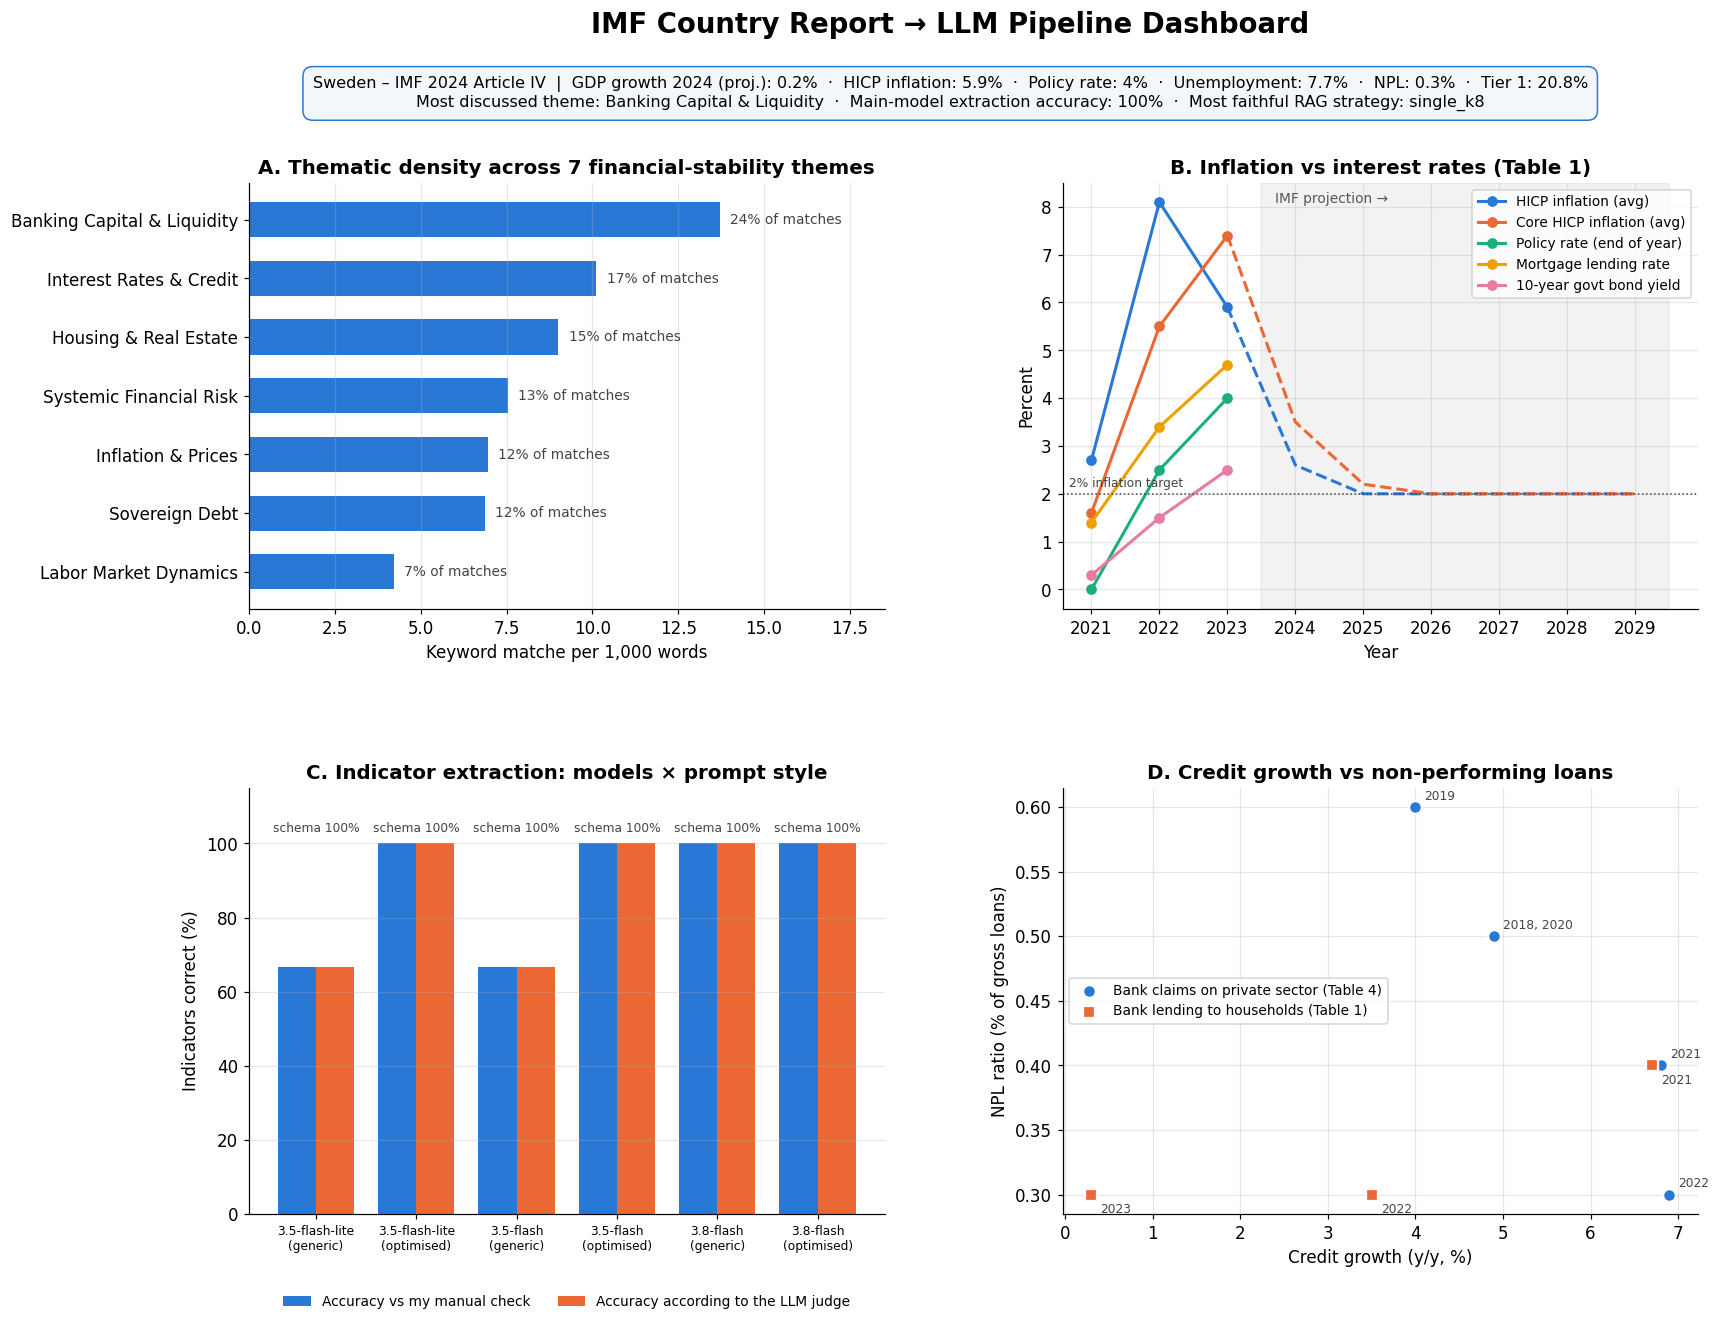

In [34]:
def series(key):

    part = trends_long[trends_long["series_key"] == key]
    return part["year"].to_numpy(), part["value"].to_numpy(), part["is_projection"].to_numpy()


def short_run_label(run):
    model, style = run.split(" | ")
    return model.replace("gemini-", "") + ("\n(optimised)" if style == "optimised" else "\n(generic)")


def plot_theme_density(ax):
    data = theme_summary.sort_values("density_per_1000_words")
    bars = ax.barh(data["theme"], data["density_per_1000_words"], color=COLORS[0], height=0.6)
    for bar, share in zip(bars, data["share_of_matches_pct"]):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2, f"{share:.0f}% of matches",
                va="center", fontsize=9, color="#444444")
    ax.set_xlabel("Keyword matche per 1,000 words")
    ax.set_title("A. Thematic density across 7 financial-stability themes")
    ax.set_xlim(0, data["density_per_1000_words"].max() * 1.35)
    ax.grid(axis="y", visible=False)


def plot_inflation_vs_rates(ax):
    lines = [("hicp_inflation_avg", "HICP inflation (avg)"), ("core_inflation_avg", "Core HICP inflation (avg)"),
             ("policy_rate", "Policy rate (end of year)"), ("mortgage_lending_rate", "Mortgage lending rate"),
             ("ten_year_bond_yield", "10-year govt bond yield")]
    if trends_long.empty:
        ax.text(0.5, 0.5, "No time series were extracted", ha="center", transform=ax.transAxes)
        return
    first_projection = None
    for colour, (key, label) in zip(COLORS, lines):
        years, values, projected = series(key)
        if len(years) == 0:
            continue
        ax.plot(years[~projected], values[~projected], marker="o", color=colour, lw=2, label=label)
        if projected.any():
            start = max(0, np.argmax(projected) - 1)
            ax.plot(years[start:], values[start:], ls="--", color=colour, lw=2)
            first_projection = years[projected][0]
    if first_projection is not None:
        ax.axvspan(first_projection - 0.5, trends_long["year"].max() + 0.5, color="#888888", alpha=0.1)
        ax.text(first_projection - 0.3, ax.get_ylim()[1] * 0.95, "IMF projection →", fontsize=9, color="#555555")
    ax.axhline(INFLATION_TARGET, color="#444444", lw=1, ls=":")
    ax.text(ax.get_xlim()[0] + 0.1, INFLATION_TARGET + 0.15, f"{INFLATION_TARGET:.0f}% inflation target", fontsize=8, color="#444444")
    plotted_years = trends_long[trends_long["series_key"].isin([k for k, _ in lines])]["year"]
    ax.set_xticks(range(plotted_years.min(), plotted_years.max() + 1))
    ax.set_ylabel("Percent")
    ax.set_xlabel("Year")
    ax.set_title("B. Inflation vs interest rates (Table 1)")
    ax.legend(loc="upper right", ncol=1)


def plot_model_comparison(ax):
    runs = accuracy_table["run"].tolist()
    x = np.arange(len(runs))
    width = 0.38
    ax.bar(x - width / 2, accuracy_table["accuracy"] * 100, width, color=COLORS[0], label="Accuracy vs my manual check")
    ax.bar(x + width / 2, accuracy_table["judge_estimated_accuracy"] * 100, width, color=COLORS[1],
           label="Accuracy according to the LLM judge")
    for xi, compliance, status in zip(x, accuracy_table["schema_compliance"], accuracy_table["status"]):
        label = f"schema {compliance:.0%}" if status == "ok" else "no response"
        ax.text(xi, 103, label, ha="center", fontsize=8, color="#444444")
    ax.set_xticks(x)
    ax.set_xticklabels([short_run_label(r) for r in runs], fontsize=8)
    ax.set_ylim(0, 115)
    ax.set_ylabel("Indicators correct (%)")
    ax.set_title("C. Indicator extraction: models × prompt style")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
    ax.grid(axis="x", visible=False)


def plot_credit_vs_npl(ax):
    npl_years, npl_values, _ = series("npl_ratio")
    if len(npl_years) == 0:
        ax.text(0.5, 0.5, "NPL series was not extracted", ha="center", transform=ax.transAxes)
        return
    npl = dict(zip(npl_years, npl_values))
    label_offsets = [(6, 5), (6, -12)]
    for colour, marker, offset, (key, label) in zip(COLORS, ["o", "s"], label_offsets,
                                                    [("private_credit_growth", "Bank claims on private sector (Table 4)"),
                                                     ("bank_lending_households_growth", "Bank lending to households (Table 1)")]):
        years, values, _ = series(key)
        points = [(y, v, npl[y]) for y, v in zip(years, values) if y in npl]
        if not points:
            continue
        ax.scatter([p[1] for p in points], [p[2] for p in points], s=70, color=colour, marker=marker,
                   edgecolor="white", linewidth=1.5, label=label, zorder=3)
        same_spot = {}
        for y, v, n in points:
            same_spot.setdefault((v, n), []).append(str(y))
        for (v, n), year_list in same_spot.items():
            ax.annotate(", ".join(year_list), (v, n), textcoords="offset points", xytext=offset,
                        fontsize=8, color="#444444")
    ax.set_xlabel("Credit growth (y/y, %)")
    ax.set_ylabel("NPL ratio (% of gross loans)")
    ax.set_title("D. Credit growth vs non-performing loans")
    ax.legend(loc="center left")


def executive_text():
    ind = final_indicators
    fmt = lambda v: "n/a" if v == FALLBACK_VALUE else f"{v:g}%"
    top_theme = theme_summary.sort_values("density_per_1000_words").iloc[-1]["theme"]
    best_rag = rag_summary["faithfulness"].idxmax() if rag_summary["faithfulness"].notna().any() else "n/a"
    main_acc = accuracy_table.loc[accuracy_table["run"] == f"{MAIN_MODEL} | optimised", "accuracy"]
    return (f"{COUNTRY} – IMF 2024 Article IV  |  GDP growth {FORECAST_YEAR} (proj.): {fmt(ind['gdp_growth_forecast_pct'])}  ·  "
            f"HICP inflation: {fmt(ind['headline_inflation_rate_pct'])}  ·  Policy rate: {fmt(ind['central_bank_policy_rate_pct'])}  ·  "
            f"Unemployment: {fmt(ind['unemployment_rate_pct'])}  ·  NPL: {fmt(ind['non_performing_loan_ratio'])}  ·  "
            f"Tier 1: {fmt(ind['tier_1_capital_ratio'])}\n"
            f"Most discussed theme: {top_theme}  ·  Main-model extraction accuracy: "
            f"{(main_acc.iloc[0] if len(main_acc) else float('nan')):.0%}  ·  Most faithful RAG strategy: {best_rag}")


fig = plt.figure(figsize=(17, 12.5))
grid = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.28, top=0.86)
plot_theme_density(fig.add_subplot(grid[0, 0]))
plot_inflation_vs_rates(fig.add_subplot(grid[0, 1]))
plot_model_comparison(fig.add_subplot(grid[1, 0]))
plot_credit_vs_npl(fig.add_subplot(grid[1, 1]))
fig.suptitle("IMF Country Report → LLM Pipeline Dashboard", fontsize=18, fontweight="bold", y=0.985)
fig.text(0.5, 0.925, executive_text(), ha="center", va="center", fontsize=10.5,
         bbox=dict(boxstyle="round,pad=0.6", facecolor="#f3f6fb", edgecolor="#2a78d6"))
fig.savefig(FIG_DIR / "dashboard.png")
plt.show()

### Supporting figures (each saved separately at 300 dpi for the report)

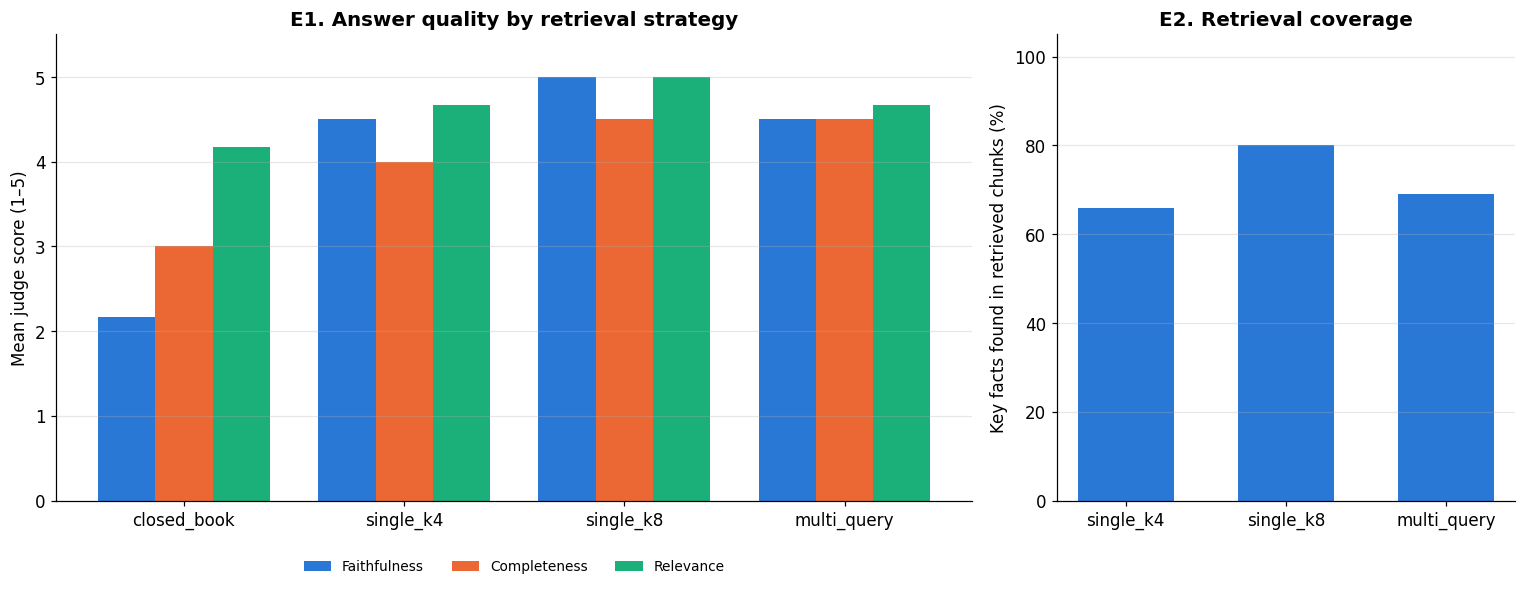

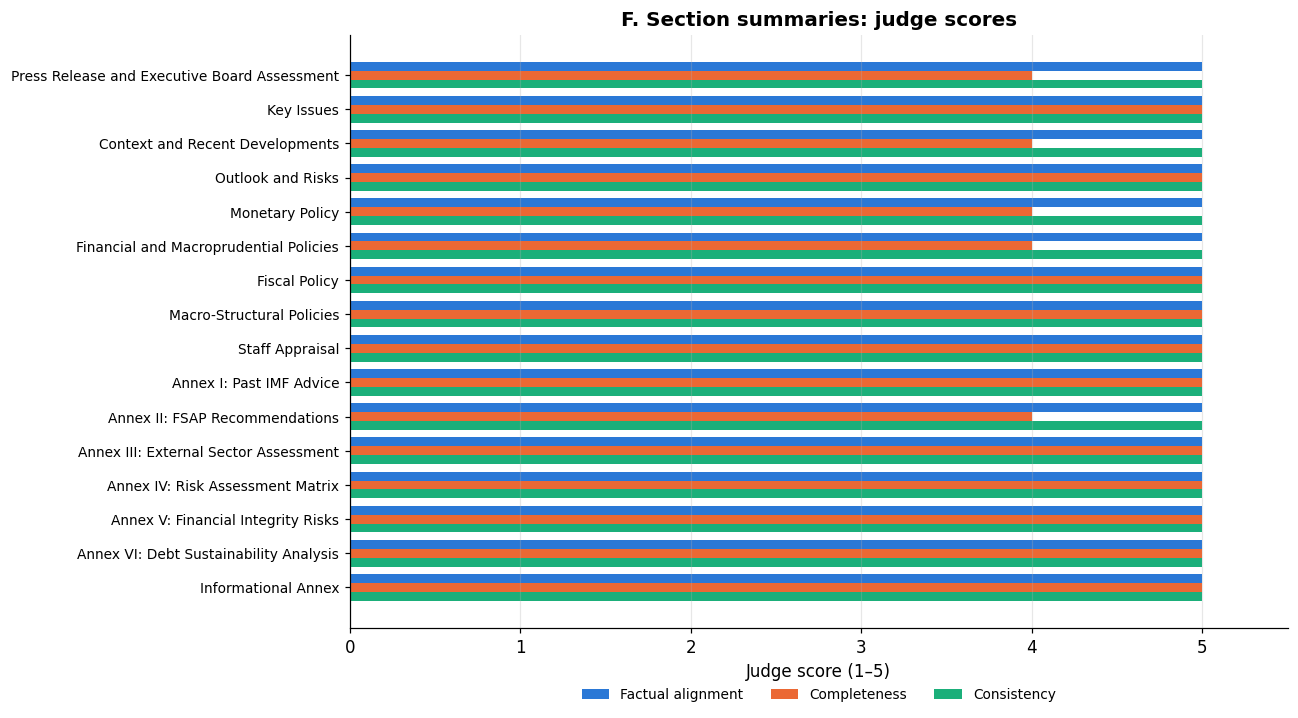

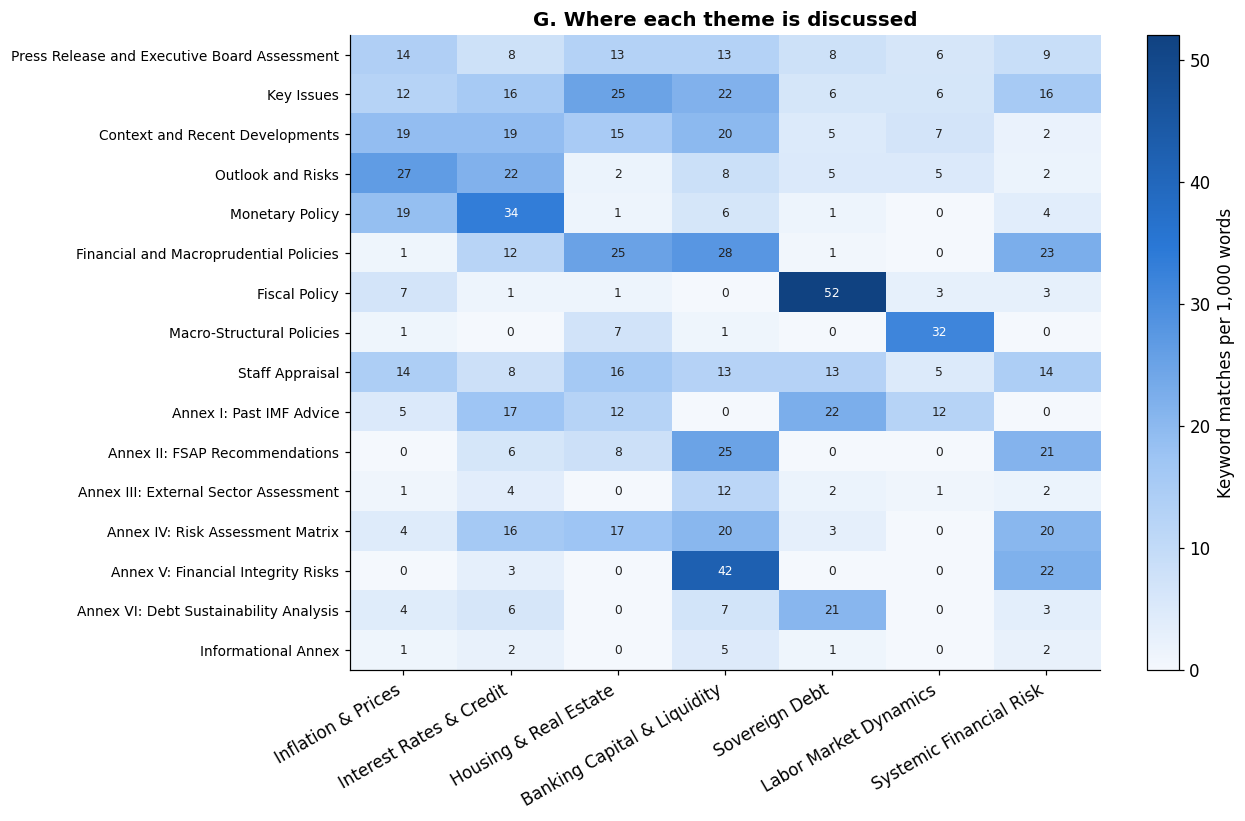

In [35]:
def save_single(plot_function, filename, size=(9, 6)):
    fig, ax = plt.subplots(figsize=size)
    plot_function(ax)
    fig.savefig(FIG_DIR / filename)
    plt.close(fig)


save_single(plot_theme_density, "fig_A_theme_density.png")
save_single(plot_inflation_vs_rates, "fig_B_inflation_vs_rates.png")
save_single(plot_model_comparison, "fig_C_model_comparison.png", size=(11, 6))
save_single(plot_credit_vs_npl, "fig_D_credit_vs_npl.png")

# RAG strategy comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [2, 1]})
criteria = ["faithfulness", "completeness", "relevance"]
x = np.arange(len(STRATEGIES))
for i, (criterion, colour) in enumerate(zip(criteria, COLORS)):
    axes[0].bar(x + (i - 1) * 0.26, rag_summary.loc[STRATEGIES, criterion], 0.26, color=colour, label=criterion.capitalize())
axes[0].set_xticks(x)
axes[0].set_xticklabels(STRATEGIES)
axes[0].set_ylim(0, 5.5)
axes[0].set_ylabel("Mean judge score (1–5)")
axes[0].set_title("E1. Answer quality by retrieval strategy")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
axes[0].grid(axis="x", visible=False)
retrieval_strategies = STRATEGIES[1:]
axes[1].bar(retrieval_strategies, rag_summary.loc[retrieval_strategies, "key_fact_coverage"] * 100, color=COLORS[0], width=0.6)
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("Key facts found in retrieved chunks (%)")
axes[1].set_title("E2. Retrieval coverage")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_E_rag_comparison.png")
plt.show()

# Section summary judge scores + number support
fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(section_df))
for i, (criterion, colour) in enumerate(zip(["factual_alignment", "completeness", "consistency"], COLORS)):
    ax.barh(y + (i - 1) * 0.26, section_df[criterion], 0.26, color=colour, label=criterion.replace("_", " ").capitalize())
ax.set_yticks(y)
ax.set_yticklabels(section_df["section"], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 5.5)
ax.set_xlabel("Judge score (1–5)")
ax.set_title("F. Section summaries: judge scores")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "fig_F_section_judge_scores.png")
plt.show()


words_per_section = {name: max(word_count(text), 1) for name, text in section_texts.items()}
heat = theme_by_section.div(pd.Series(words_per_section), axis=0) * 1000
heat = heat.loc[[s for s in section_texts if SUMMARISE.get(s)]]
fig, ax = plt.subplots(figsize=(11, 7.5))
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#9ec5f4", "#2a78d6", "#104281"])
image = ax.imshow(heat.values, cmap=blues, aspect="auto")
ax.set_xticks(range(len(THEMES)))
ax.set_xticklabels(THEMES, rotation=30, ha="right")
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(heat.index, fontsize=9)
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.values[i, j]
        ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8,
                color="white" if value > heat.values.max() * 0.55 else "#222222")
fig.colorbar(image, ax=ax, label="Keyword matches per 1,000 words")
ax.set_title("G. Where each theme is discussed")
fig.savefig(FIG_DIR / "fig_G_theme_by_section.png")
plt.show()

## Run summary

A final record of what was produced, how many API calls were made, and how long they took.

In [36]:
usage = pd.DataFrame(LLM_LOG)
usage["model_used"] = usage["model_used"].fillna("none (failed)")
usage_table = (usage.groupby(["model", "model_used", "task"])
               .agg(calls=("ok", "size"), failed=("ok", lambda s: (~s).sum()), from_cache=("cached", "sum"),
                    mean_latency_s=("latency_s", "mean"))
               .round(2).reset_index())
usage_table.to_csv(OUTPUT_DIR / "llm_usage.csv", index=False)

run_summary = {
    "report": REPORT_NAME,
    "pages": len(raw_pages),
    "chunks": len(chunks),
    "sections_summarised": len(prose_sections),
    "llm_calls": len(usage),
    "llm_calls_failed": int((~usage["ok"]).sum()) if len(usage) else 0,
    # how often Google's overload forced a backup model
    "share_answered_by_backup_model": round(float((usage["ok"] & (usage["model_used"] != usage["model"])).mean()), 3) if len(usage) else 0,
    "models": {"main": MAIN_MODEL, "judge": JUDGE_MODEL, "benchmark": BENCHMARK_MODELS},
    "core_indicators": final_indicators,
    "fallbacks_main_run": main_run["fallbacks"],
    "files": sorted(str(p.relative_to(BASE_DIR)) for p in BASE_DIR.rglob("*") if p.is_file() and "llm_cache" not in str(p)),
}
save_json(run_summary, "run_summary.json")
print(json.dumps({k: v for k, v in run_summary.items() if k != "files"}, indent=2))
usage_table

saved /content/drive/MyDrive/imf_pipeline/outputs/run_summary.json
{
  "report": "IMF Country Report No. 24/70 - Sweden: 2024 Article IV Consultation",
  "pages": 56,
  "chunks": 120,
  "sections_summarised": 16,
  "llm_calls": 87,
  "llm_calls_failed": 0,
  "share_answered_by_backup_model": 0.644,
  "models": {
    "main": "gemini-3.5-flash",
    "judge": "gemini-3.8-flash",
    "benchmark": [
      "gemini-3.5-flash-lite",
      "gemini-3.5-flash",
      "gemini-3.8-flash"
    ]
  },
  "core_indicators": {
    "country_name": "Sweden",
    "gdp_growth_forecast_pct": 0.2,
    "headline_inflation_rate_pct": 5.9,
    "central_bank_policy_rate_pct": 4.0,
    "non_performing_loan_ratio": 0.3,
    "unemployment_rate_pct": 7.7,
    "tier_1_capital_ratio": 20.8
  },
  "fallbacks_main_run": {}
}


,model,model_used,task,calls,failed,from_cache,mean_latency_s
0,gemini-3.1-flash-lite,gemini-3.1-flash-lite,rag_multi_query,4,0,4,0.95
1,gemini-3.1-flash-lite,gemini-3.1-flash-lite,rag_single_k4,4,0,4,1.01
2,gemini-3.1-flash-lite,gemini-3.1-flash-lite,rag_single_k8,4,0,4,1.87
3,gemini-3.5-flash,gemini-2.5-flash,section_shorten,1,0,1,7.41
4,gemini-3.5-flash,gemini-2.5-flash,section_summary,6,0,6,5.57
5,gemini-3.5-flash,gemini-3.1-flash-lite,query_variants,3,0,3,0.99
6,gemini-3.5-flash,gemini-3.1-flash-lite,rag_closed_book,4,0,4,1.45
7,gemini-3.5-flash,gemini-3.5-flash,exec_generic,1,0,0,13.98
8,gemini-3.5-flash,gemini-3.5-flash,exec_optimised,1,0,0,16.12
9,gemini-3.5-flash,gemini-3.5-flash,indicators_generic,1,0,1,9.35
